# Syllabic Homophonic Cipher: Glyph → Hebrew Syllable

**Hypothesis:** Each Voynich glyph encodes a **complete Hebrew syllable** (2-3 characters), and multiple glyphs can represent the same syllable (homophonic cipher).

**Motivation:**
- 166 glyphs is too many for an alphabet (~27 chars) but reasonable for a syllabary with homophonic variants
- MI does not amplify glyph→syllable (0.92×), consistent with glyphs ALREADY being syllabic units
- 73% of glyphs position-locked: position could determine which homophonic variant is used

**Strategy:** Reuse the character LSTM from neural_v2. When glyph G maps to syllable "bar" (ב,ר), `apply_word` concatenates the characters of all syllables and the LSTM scores the resulting sequence.

In [1]:
# ── Cell 1: Imports ──────────────────────────────────────────────────
import re, math, random, json, warnings, time, copy
from collections import Counter, defaultdict
from itertools import combinations
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import requests
from scipy.spatial.distance import jensenshannon
from tqdm.notebook import tqdm

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader

warnings.filterwarnings('ignore')

plt.rcParams.update({
    'figure.dpi': 130, 'savefig.dpi': 180,
    'font.size': 10, 'axes.titlesize': 11,
    'figure.facecolor': 'white',
})

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {DEVICE}')
print('Imports OK')

Device: cuda
Imports OK


In [2]:
# ── Cell 2: Load Voynich corpus ─────────────────────────────────────
STA_PATH = 'corpus/voynich_sta.txt'

def parsear_sta_completo(filepath):
    tokens = []
    with open(filepath, 'r', encoding='utf-8') as f:
        for linea in f:
            linea = linea.strip()
            if not linea or linea.startswith('#'):
                continue
            if re.match(r'^<[^>]+>\s*<!', linea):
                continue
            match = re.match(r'^<[^>]+>\s+(.*)', linea)
            if not match:
                continue
            texto = match.group(1).strip()
            texto = re.sub(r'\{[^}]*\}', '', texto)
            texto = re.sub(r'<[^>]*>',   '', texto)
            texto = re.sub(r'-',          '.', texto)
            texto = texto.strip()
            if not texto:
                continue
            for palabra_raw in texto.split('.'):
                palabra_raw = palabra_raw.strip()
                if not palabra_raw:
                    continue
                glifos = re.findall(r'[A-Z][0-9a-z]', palabra_raw)
                if glifos:
                    tokens.extend(glifos)
                    tokens.append('.')
    return tokens


def tokens_a_palabras(tokens):
    palabras, actual = [], []
    for t in tokens:
        if t == '.':
            if actual:
                palabras.append(actual)
                actual = []
        else:
            actual.append(t)
    if actual:
        palabras.append(actual)
    return palabras


# ── Segmentation and positional classification ──

def construir_matriz_transicion_intrapalabra(palabras):
    all_glyphs = sorted({g for p in palabras for g in p})
    index = {g: i for i, g in enumerate(all_glyphs)}
    n = len(all_glyphs)
    M_raw = np.zeros((n, n))
    for palabra in palabras:
        for i in range(len(palabra) - 1):
            r, c = index[palabra[i]], index[palabra[i + 1]]
            M_raw[r, c] += 1
    row_sums = M_raw.sum(axis=1, keepdims=True)
    row_sums[row_sums == 0] = 1
    M_prob = M_raw / row_sums
    return M_raw, M_prob, all_glyphs, index


def segmentar_silabas_tp(palabras, M_prob, tokens_tr, index_tr, threshold_percentile=20):
    all_trans_probs = []
    for palabra in palabras:
        for i in range(len(palabra) - 1):
            g1, g2 = palabra[i], palabra[i + 1]
            if g1 in index_tr and g2 in index_tr:
                all_trans_probs.append(M_prob[index_tr[g1], index_tr[g2]])
    threshold_val = np.percentile(all_trans_probs, threshold_percentile)
    silabas_por_palabra = []
    for palabra in palabras:
        if len(palabra) == 0:
            continue
        syl = [palabra[0]]
        for i in range(len(palabra) - 1):
            g1, g2 = palabra[i], palabra[i + 1]
            p = M_prob[index_tr[g1], index_tr[g2]] if (g1 in index_tr and g2 in index_tr) else 0.0
            if p < threshold_val:
                silabas_por_palabra.append(tuple(syl))
                syl = [g2]
            else:
                syl.append(g2)
        if syl:
            silabas_por_palabra.append(tuple(syl))
        silabas_por_palabra.append(None)
    return silabas_por_palabra, all_trans_probs, threshold_val


def catalogar_silabas(silabas_por_palabra):
    syl_freq = Counter()
    syl_per_word = []
    syl_lengths = Counter()
    count_in_word = 0
    for item in silabas_por_palabra:
        if item is None:
            if count_in_word > 0:
                syl_per_word.append(count_in_word)
            count_in_word = 0
        else:
            syl_freq[item] += 1
            syl_lengths[len(item)] += 1
            count_in_word += 1
    if count_in_word > 0:
        syl_per_word.append(count_in_word)
    return syl_freq, syl_per_word, syl_lengths


def clasificar_silabas_posicionalmente(silabas_por_palabra, min_freq=5):
    words_as_syls = []
    current = []
    for item in silabas_por_palabra:
        if item is None:
            if current:
                words_as_syls.append(current)
            current = []
        else:
            current.append(item)
    if current:
        words_as_syls.append(current)
    pos_counts = defaultdict(lambda: {'inicio': 0, 'medio': 0, 'final': 0, 'total': 0})
    for word_syls in words_as_syls:
        n = len(word_syls)
        for i, syl in enumerate(word_syls):
            pos_counts[syl]['total'] += 1
            if n == 1:
                pos_counts[syl]['inicio'] += 1
                pos_counts[syl]['final'] += 1
            elif i == 0:
                pos_counts[syl]['inicio'] += 1
            elif i == n - 1:
                pos_counts[syl]['final'] += 1
            else:
                pos_counts[syl]['medio'] += 1
    clase_silaba = {}
    stats = {}
    for syl, counts in pos_counts.items():
        if counts['total'] < min_freq:
            continue
        total = counts['total']
        r_ini = counts['inicio'] / total
        r_fin = counts['final'] / total
        r_med = counts['medio'] / total
        if r_ini >= 0.60 and r_fin < 0.30:
            clase = 'onset'
        elif r_fin >= 0.60 and r_ini < 0.30:
            clase = 'coda'
        elif r_med >= 0.40:
            clase = 'nuclear'
        else:
            clase = 'free'
        clase_silaba[syl] = clase
        stats[syl] = {'clase': clase, 'inicio': r_ini, 'medio': r_med,
                       'final': r_fin, 'total': total}
    return clase_silaba, stats


def syls_to_words(syls_flat):
    words, current = [], []
    for item in syls_flat:
        if item is None:
            if current:
                words.append(current)
            current = []
        else:
            current.append(item)
    if current:
        words.append(current)
    return words


def clasificar_glifos(palabras, WORDS_SYL_V, clase_silaba_v, VOCAB):
    glyph_in_class = defaultdict(Counter)
    glyph_position = defaultdict(Counter)
    for word_syls in WORDS_SYL_V:
        for syl in word_syls:
            clase = clase_silaba_v.get(syl, 'free')
            for i, g in enumerate(syl):
                glyph_in_class[g][clase] += 1
                if i == 0:
                    glyph_position[g]['inicio'] += 1
                elif i == len(syl) - 1:
                    glyph_position[g]['fin'] += 1
                else:
                    glyph_position[g]['medio'] += 1
    glyph_role = {}
    glyph_stats = {}
    for g in VOCAB:
        counts = glyph_in_class[g]
        total = sum(counts.values())
        if total < 5:
            glyph_role[g] = '?'
            glyph_stats[g] = {'role': '?', 'total': total, 'pct_nuclear': 0}
            continue
        pct_nuclear = counts.get('nuclear', 0) / total
        pct_onset = counts.get('onset', 0) / total
        pct_coda = counts.get('coda', 0) / total
        glyph_role[g] = 'V' if pct_nuclear > 0.40 else 'C'
        glyph_stats[g] = {
            'role': glyph_role[g], 'total': total,
            'pct_nuclear': pct_nuclear, 'pct_onset': pct_onset,
            'pct_coda': pct_coda, 'pct_free': counts.get('free', 0) / total,
            'pos_inicio': glyph_position[g].get('inicio', 0),
            'pos_medio': glyph_position[g].get('medio', 0),
            'pos_fin': glyph_position[g].get('fin', 0),
        }
    return glyph_role, glyph_stats


# ── Load and process Voynich ──
tokens_voynich = parsear_sta_completo(STA_PATH)
palabras = tokens_a_palabras(tokens_voynich)
corpus_plano = [g for p in palabras for g in p]
VOCAB = sorted(set(corpus_plano))
N_VOYNICH = len(palabras)
glyph_freq = Counter(corpus_plano)

M_raw, M_prob, tokens_tr, index_tr = construir_matriz_transicion_intrapalabra(palabras)
SILABAS_VOYNICH, _, threshold_val = segmentar_silabas_tp(
    palabras, M_prob, tokens_tr, index_tr, threshold_percentile=20)
syl_freq_v, syl_per_word_v, syl_lengths_v = catalogar_silabas(SILABAS_VOYNICH)
clase_silaba_v, stats_syl_v = clasificar_silabas_posicionalmente(SILABAS_VOYNICH, min_freq=5)
WORDS_SYL_V = syls_to_words(SILABAS_VOYNICH)
glyph_role, glyph_stats = clasificar_glifos(palabras, WORDS_SYL_V, clase_silaba_v, VOCAB)

n_c = sum(1 for g in VOCAB if glyph_role[g] == 'C')
n_v = sum(1 for g in VOCAB if glyph_role[g] == 'V')
n_q = sum(1 for g in VOCAB if glyph_role[g] == '?')
print(f'Voynich: {N_VOYNICH:,} words, {len(corpus_plano):,} tokens, {len(VOCAB)} glyphs')
print(f'Classification: C={n_c}, V={n_v}, ?={n_q}')

Voynich: 37,087 palabras, 157,254 tokens, 166 glifos
Clasificación: C=70, V=5, ?=91


In [3]:
# ── Cell 3: Load Hebrew corpus + CharLM baseline + grammar anchors ──

def descargar_hebreo():
    books = ['Genesis', 'Exodus', 'Leviticus', 'Numbers', 'Deuteronomy']
    base_url = ('https://raw.githubusercontent.com/Sefaria/Sefaria-Export/'
                'master/json/Tanakh/Torah/{}/Hebrew/Tanach%20with%20Text%20Only.json')
    todas_palabras = []
    for libro in libros:
        url = base_url.format(libro)
        print(f'  Downloading {libro}...')
        resp = requests.get(url, timeout=30)
        resp.raise_for_status()
        data = resp.json()
        for capitulo in data['text']:
            for versiculo in capitulo:
                texto = re.sub(r'[\u0591-\u05C7]', '', versiculo)
                pals = re.findall(r'[\u05D0-\u05EA]+', texto)
                for p in pals:
                    chars = list(p)
                    if 2 <= len(chars) <= 15:
                        todas_palabras.append(chars)
    print(f'  Hebrew total: {len(todas_palabras):,} words')
    return todas_palabras

print('Downloading Hebrew corpus (Torah)...')
hebrew_words_full = descargar_hebreo()

# Subsample
rng_sub = np.random.default_rng(42)
if len(hebrew_words_full) > N_VOYNICH:
    idx = rng_sub.choice(len(hebrew_words_full), size=N_VOYNICH, replace=False)
    hebrew_words = [hebrew_words_full[i] for i in sorted(idx)]
else:
    hebrew_words = hebrew_words_full
print(f'Hebrew subsampled: {len(hebrew_words):,} words')

# Hebrew C/V classification
HEBREW_VOWELS = set('אהוי')  # matres lectionis
target_chars_heb = sorted(set(c for w in hebrew_words for c in w))
char_role_heb = {c: 'V' if c in HEBREW_VOWELS else 'C' for c in target_chars_heb}
n_c_h = sum(1 for c in target_chars_heb if char_role_heb[c] == 'C')
n_v_h = sum(1 for c in target_chars_heb if char_role_heb[c] == 'V')
print(f'Hebrew: {len(target_chars_heb)} chars (C={n_c_h}, V={n_v_h})')

# ── Trigram CharLM baseline (Witten-Bell) ──
class CharLM:
    def __init__(self, order=3):
        self.order = order
        self.trigram_counts = defaultdict(Counter)
        self.bigram_counts = defaultdict(Counter)
        self.unigram_counts = Counter()
        self.vocab = set()
        self.total = 0
        self._V = 0

    def fit(self, words):
        BOS, EOS = '<w>', '</w>'
        for word in words:
            seq = [BOS, BOS] + list(word) + [EOS]
            for c in seq:
                self.vocab.add(c)
                self.unigram_counts[c] += 1
                self.total += 1
            for i in range(len(seq) - 1):
                self.bigram_counts[seq[i]][seq[i+1]] += 1
            for i in range(len(seq) - 2):
                ctx = (seq[i], seq[i+1])
                self.trigram_counts[ctx][seq[i+2]] += 1
        self._V = len(self.vocab)

    def _log_prob_trigram(self, c1, c2, c3):
        ctx = (c1, c2)
        tri_counts = self.trigram_counts[ctx]
        tri_total = sum(tri_counts.values())
        if tri_total > 0:
            tri_seen = len(tri_counts)
            count = tri_counts.get(c3, 0)
            if count > 0:
                prob = count / (tri_total + tri_seen)
                return math.log2(max(prob, 1e-20))
            else:
                lambda_bo = tri_seen / (tri_total + tri_seen)
                bi_counts = self.bigram_counts[c2]
                bi_total = sum(bi_counts.values())
                if bi_total > 0:
                    bi_seen = len(bi_counts)
                    bi_count = bi_counts.get(c3, 0)
                    if bi_count > 0:
                        prob = lambda_bo * bi_count / (bi_total + bi_seen)
                    else:
                        lambda_bo2 = bi_seen / (bi_total + bi_seen)
                        prob = lambda_bo * lambda_bo2 * (self.unigram_counts.get(c3, 0) + 1) / (self.total + self._V)
                else:
                    prob = lambda_bo * (self.unigram_counts.get(c3, 0) + 1) / (self.total + self._V)
                return math.log2(max(prob, 1e-20))
        else:
            bi_counts = self.bigram_counts[c2]
            bi_total = sum(bi_counts.values())
            if bi_total > 0:
                bi_seen = len(bi_counts)
                count = bi_counts.get(c3, 0)
                if count > 0:
                    prob = count / (bi_total + bi_seen)
                else:
                    lambda_bo = bi_seen / (bi_total + bi_seen)
                    prob = lambda_bo * (self.unigram_counts.get(c3, 0) + 1) / (self.total + self._V)
                return math.log2(max(prob, 1e-20))
            else:
                prob = (self.unigram_counts.get(c3, 0) + 1) / (self.total + self._V)
                return math.log2(max(prob, 1e-20))

    def log_prob(self, word):
        BOS, EOS = '<w>', '</w>'
        seq = [BOS, BOS] + list(word) + [EOS]
        lp = 0.0
        for i in range(2, len(seq)):
            lp += self._log_prob_trigram(seq[i-2], seq[i-1], seq[i])
        return lp

    def perplexity(self, words):
        total_lp, total_n = 0.0, 0
        for word in words:
            total_lp += self.log_prob(word)
            total_n += len(word) + 1
        if total_n == 0:
            return float('inf')
        return 2.0 ** (-total_lp / total_n)

# Train baseline
char_lm_baseline = CharLM(order=3)
char_lm_baseline.fit(hebrew_words)
ppx_baseline = char_lm_baseline.perplexity(hebrew_words)
print(f'CharLM baseline native PPX: {ppx_baseline:.2f}')

# ── Grammar anchors ──
HEBREW_PREFIXES = set('והבכלמש')
HEBREW_SUFFIXES = set('התםןך')
HEBREW_ROOT_CONSONANTS = set('אבגדהוזחטיכלמנסעפצקרשת') - HEBREW_PREFIXES - HEBREW_SUFFIXES

GRAMMAR_ANCHORS = {
    'D1': HEBREW_PREFIXES,
    'K1': HEBREW_PREFIXES | {'ש'},
    'L1': {'ל', 'ה', 'ב', 'מ'},
    'Q1': HEBREW_ROOT_CONSONANTS,
    'Q2': HEBREW_ROOT_CONSONANTS,
    'A2': HEBREW_SUFFIXES,
    'C1': HEBREW_SUFFIXES,
}

def build_glyph_grammar_roles(palabras, glyph_stats, VOCAB):
    glyph_grammar_role = {}
    direct_rules = {
        'D1': 'prefix', 'K1': 'classifier', 'L1': 'prefix',
        'Q1': 'root', 'Q2': 'root',
        'A2': 'suffix', 'C1': 'suffix',
    }
    for g in VOCAB:
        if g in direct_rules:
            glyph_grammar_role[g] = direct_rules[g]
            continue
        s = glyph_stats.get(g, {})
        total = s.get('total', 0)
        if total < 10:
            continue
        pos_ini = s.get('pos_inicio', 0)
        pos_fin = s.get('pos_fin', 0)
        pos_med = s.get('pos_medio', 0)
        pos_total = pos_ini + pos_fin + pos_med
        if pos_total == 0:
            continue
        pct_onset = s.get('pct_onset', 0)
        pct_coda = s.get('pct_coda', 0)
        pct_nuclear = s.get('pct_nuclear', 0)
        r_ini = pos_ini / pos_total
        r_fin = pos_fin / pos_total
        if pct_onset > 0.50 and r_ini > 0.50:
            glyph_grammar_role[g] = 'prefix'
        elif pct_coda > 0.50 and r_fin > 0.50:
            glyph_grammar_role[g] = 'suffix'
        elif pct_nuclear > 0.40:
            glyph_grammar_role[g] = 'root'
    role_to_anchor = {
        'prefix': HEBREW_PREFIXES,
        'classifier': HEBREW_PREFIXES | {'ש'},
        'root': HEBREW_ROOT_CONSONANTS,
        'suffix': HEBREW_SUFFIXES,
    }
    glyph_anchor_sets = {}
    for g, role in glyph_grammar_role.items():
        glyph_anchor_sets[g] = role_to_anchor.get(role, set())
    return glyph_grammar_role, glyph_anchor_sets

glyph_grammar_role, glyph_anchor_sets = build_glyph_grammar_roles(
    palabras, glyph_stats, VOCAB)

role_counts = Counter(glyph_grammar_role.values())
print(f'\nGrammar anchors: {len(glyph_grammar_role)} glyphs')
for role, cnt in sorted(role_counts.items(), key=lambda x: -x[1]):
    print(f'  {role}: {cnt}')

Descargando corpus hebreo (Torah)...
  Descargando Genesis...
  Descargando Exodus...
  Descargando Leviticus...
  Descargando Numbers...
  Descargando Deuteronomy...
  Hebreo total: 80,051 palabras
Hebreo subsampleado: 37,087 palabras
Hebreo: 27 chars (C=23, V=4)
CharLM baseline PPX nativa: 7.32

Grammar anchors: 12 glifos
  root: 7
  suffix: 2
  prefix: 2
  classifier: 1


In [4]:
# ── Cell 4: NeuralCharLM — LSTM architecture ─────────────────────────

class CharDataset(Dataset):
    def __init__(self, words, char2idx):
        self.samples = []
        bos = char2idx['<w>']
        eos = char2idx['</w>']
        for word in words:
            indices = [bos, bos] + [char2idx.get(c, char2idx.get('<unk>', 0)) for c in word] + [eos]
            for i in range(2, len(indices)):
                ctx = indices[i-2:i]
                target = indices[i]
                self.samples.append((ctx, target))

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        ctx, target = self.samples[idx]
        return torch.tensor(ctx, dtype=torch.long), torch.tensor(target, dtype=torch.long)


class NeuralCharLM(nn.Module):
    def __init__(self, vocab_size, embed_dim=32, hidden_dim=192, n_layers=2, dropout=0.2):
        super().__init__()
        self.vocab_size = vocab_size
        self.embed_dim = embed_dim
        self.hidden_dim = hidden_dim
        self.n_layers = n_layers
        self.embedding = nn.Embedding(vocab_size, embed_dim)
        self.lstm = nn.LSTM(embed_dim, hidden_dim, num_layers=n_layers,
                           dropout=dropout if n_layers > 1 else 0.0,
                           batch_first=True)
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(hidden_dim, vocab_size)
        self.char2idx = None
        self.idx2char = None

    def forward(self, x, hidden=None):
        emb = self.dropout(self.embedding(x))
        out, hidden = self.lstm(emb, hidden)
        out = self.dropout(out)
        logits = self.fc(out)
        return logits, hidden

    def log_prob(self, word, temperature=1.0):
        self.eval()
        with torch.no_grad():
            bos = self.char2idx['<w>']
            eos = self.char2idx['</w>']
            unk = self.char2idx.get('<unk>', 0)
            indices = [bos, bos] + [self.char2idx.get(c, unk) for c in word] + [eos]
            total_lp = 0.0
            for i in range(2, len(indices)):
                ctx = torch.tensor([[indices[i-2], indices[i-1]]], device=DEVICE)
                logits, _ = self.forward(ctx)
                logits_t = logits[0, -1, :] / temperature
                log_probs = torch.log_softmax(logits_t, dim=0)
                total_lp += log_probs[indices[i]].item() / math.log(2)
            return total_lp

    def batch_log_prob(self, words, temperature=1.0):
        self.eval()
        bos = self.char2idx['<w>']
        eos = self.char2idx['</w>']
        unk = self.char2idx.get('<unk>', 0)
        with torch.no_grad():
            all_ctx = []
            all_tgt = []
            word_boundaries = [0]
            for word in words:
                seq = [bos, bos] + [self.char2idx.get(c, unk) for c in word] + [eos]
                for i in range(2, len(seq)):
                    all_ctx.append([seq[i-2], seq[i-1]])
                    all_tgt.append(seq[i])
                word_boundaries.append(len(all_ctx))
            n_total = len(all_ctx)
            if n_total == 0:
                return np.zeros(len(words))
            ctx_t = torch.tensor(all_ctx, device=DEVICE)
            tgt_t = torch.tensor(all_tgt, device=DEVICE)
            CHUNK = 16384
            all_lps = []
            for start in range(0, n_total, CHUNK):
                end = min(start + CHUNK, n_total)
                logits, _ = self.forward(ctx_t[start:end])
                logits_last = logits[:, -1, :] / temperature
                log_p = torch.log_softmax(logits_last, dim=-1)
                target_lp = log_p.gather(1, tgt_t[start:end].unsqueeze(1)).squeeze(1)
                all_lps.append(target_lp)
            all_lps = torch.cat(all_lps).cpu().numpy() / math.log(2)
            word_lps = np.zeros(len(words))
            for wi in range(len(words)):
                start = word_boundaries[wi]
                end = word_boundaries[wi + 1]
                if start < end:
                    word_lps[wi] = all_lps[start:end].sum()
            return word_lps

    def perplexity(self, words, temperature=1.0):
        self.eval()
        word_lps = self.batch_log_prob(words, temperature)
        total_lp = word_lps.sum()
        total_n = sum(len(w) + 1 for w in words)
        if total_n == 0:
            return float('inf')
        return 2.0 ** (-total_lp / total_n)


# ── Build vocabulary and indices ──
all_chars_heb = sorted(set(c for w in hebrew_words for c in w))
special_tokens = ['<pad>', '<w>', '</w>', '<unk>']
char_vocab = special_tokens + all_chars_heb
char2idx = {c: i for i, c in enumerate(char_vocab)}
idx2char = {i: c for c, i in char2idx.items()}

print(f'Neural LM vocab: {len(char_vocab)} tokens ({len(all_chars_heb)} chars + {len(special_tokens)} special)')
n_params = sum(p.numel() for p in NeuralCharLM(len(char_vocab)).parameters())
print(f'Parameters: {n_params:,}')

Neural LM vocab: 31 tokens (27 chars + 4 special)
Parámetros: 476,991


Train: 29,670 words, Val: 7,417 words
Train samples: 142,813, Val samples: 35,563

Entrenando Neural LM (30 epochs, patience=5)...
  Epoch  1: train_loss=2.3421, val_loss=2.1351, lr=0.001995
  Epoch  5: train_loss=2.0597, val_loss=2.0316, lr=0.001866
  Epoch 10: train_loss=2.0337, val_loss=2.0200, lr=0.001500
  Epoch 15: train_loss=2.0199, val_loss=2.0114, lr=0.001000
  Epoch 20: train_loss=2.0110, val_loss=2.0080, lr=0.000500
  Epoch 25: train_loss=2.0043, val_loss=2.0047, lr=0.000134
  Epoch 30: train_loss=2.0013, val_loss=2.0043, lr=0.000000

Entrenamiento completado en 47.9s

Perplexity en validación (2000 words):
  CharLM trigram (baseline): 7.37
  NeuralCharLM (T=1.0):     7.49


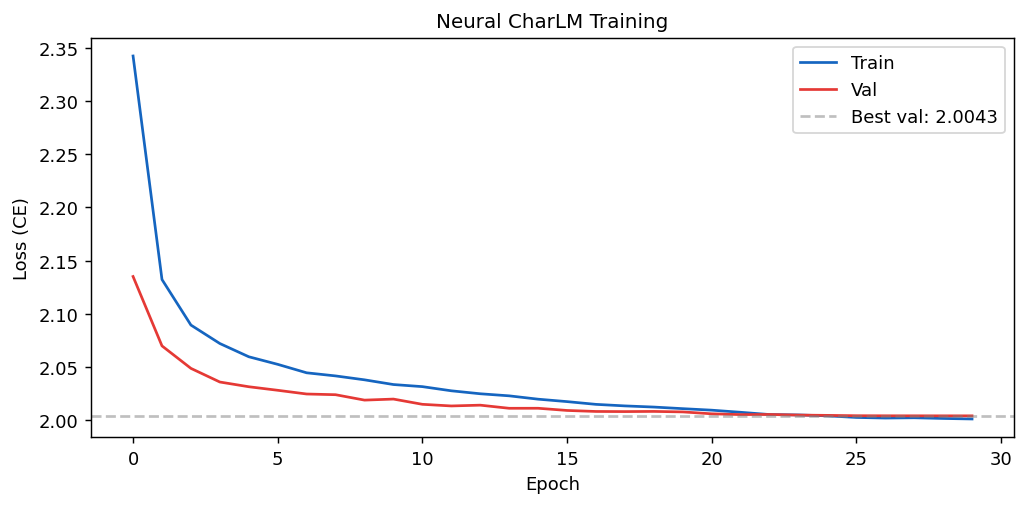

In [5]:
# ── Cell 5: Neural LM training ──────────────────────────────

rng_split = np.random.default_rng(42)
n_val = int(0.2 * len(hebrew_words))
perm = rng_split.permutation(len(hebrew_words))
val_idx = set(perm[:n_val])
train_words = [hebrew_words[i] for i in range(len(hebrew_words)) if i not in val_idx]
val_words = [hebrew_words[i] for i in range(len(hebrew_words)) if i in val_idx]
print(f'Train: {len(train_words):,} words, Val: {len(val_words):,} words')

train_dataset = CharDataset(train_words, char2idx)
val_dataset = CharDataset(val_words, char2idx)
train_loader = DataLoader(train_dataset, batch_size=256, shuffle=True, num_workers=0)
val_loader = DataLoader(val_dataset, batch_size=256, shuffle=False, num_workers=0)
print(f'Train samples: {len(train_dataset):,}, Val samples: {len(val_dataset):,}')

neural_lm = NeuralCharLM(len(char_vocab), embed_dim=32, hidden_dim=192,
                          n_layers=2, dropout=0.2).to(DEVICE)
neural_lm.char2idx = char2idx
neural_lm.idx2char = idx2char

optimizer = optim.AdamW(neural_lm.parameters(), lr=2e-3, weight_decay=1e-4)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=30)
criterion = nn.CrossEntropyLoss(ignore_index=char2idx['<pad>'])

N_EPOCHS = 30
PATIENCE = 5
best_val_loss = float('inf')
patience_counter = 0
train_losses = []
val_losses = []

print(f'\nTraining Neural LM ({N_EPOCHS} epochs, patience={PATIENCE})...')
t0 = time.time()

for epoch in range(N_EPOCHS):
    neural_lm.train()
    epoch_loss = 0.0
    n_batches = 0
    for ctx_batch, target_batch in train_loader:
        ctx_batch = ctx_batch.to(DEVICE)
        target_batch = target_batch.to(DEVICE)
        optimizer.zero_grad()
        logits, _ = neural_lm(ctx_batch)
        loss = criterion(logits[:, -1, :], target_batch)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(neural_lm.parameters(), 1.0)
        optimizer.step()
        epoch_loss += loss.item()
        n_batches += 1
    train_loss = epoch_loss / max(n_batches, 1)
    train_losses.append(train_loss)

    neural_lm.eval()
    val_loss = 0.0
    n_val_batches = 0
    with torch.no_grad():
        for ctx_batch, target_batch in val_loader:
            ctx_batch = ctx_batch.to(DEVICE)
            target_batch = target_batch.to(DEVICE)
            logits, _ = neural_lm(ctx_batch)
            loss = criterion(logits[:, -1, :], target_batch)
            val_loss += loss.item()
            n_val_batches += 1
    val_loss = val_loss / max(n_val_batches, 1)
    val_losses.append(val_loss)
    scheduler.step()

    if (epoch + 1) % 5 == 0 or epoch == 0:
        print(f'  Epoch {epoch+1:2d}: train_loss={train_loss:.4f}, val_loss={val_loss:.4f}, '
              f'lr={scheduler.get_last_lr()[0]:.6f}')

    if val_loss < best_val_loss - 1e-4:
        best_val_loss = val_loss
        patience_counter = 0
        best_state_dict = copy.deepcopy(neural_lm.state_dict())
    else:
        patience_counter += 1
        if patience_counter >= PATIENCE:
            print(f'  Early stopping at epoch {epoch+1}')
            break

elapsed = time.time() - t0
print(f'\nTraining completed in {elapsed:.1f}s')

neural_lm.load_state_dict(best_state_dict)

neural_val_ppx = neural_lm.perplexity(val_words[:2000], temperature=1.0)
baseline_val_ppx = char_lm_baseline.perplexity(val_words[:2000])
print(f'\nPerplexity on validation (2000 words):')
print(f'  CharLM trigram (baseline): {baseline_val_ppx:.2f}')
print(f'  NeuralCharLM (T=1.0):     {neural_val_ppx:.2f}')

fig, ax = plt.subplots(1, 1, figsize=(8, 4))
ax.plot(train_losses, label='Train', color='#1565C0')
ax.plot(val_losses, label='Val', color='#E53935')
ax.axhline(best_val_loss, linestyle='--', color='gray', alpha=0.5, label=f'Best val: {best_val_loss:.4f}')
ax.set_xlabel('Epoch')
ax.set_ylabel('Loss (CE)')
ax.set_title('Neural CharLM Training')
ax.legend()
plt.tight_layout()
plt.show()

In [6]:
# ── Cell 6: Hebrew syllable inventory (TP segmentation) ──────────

def compute_transition_probs_hebrew(hebrew_words):
    """Compute bigram transition probabilities within Hebrew words."""
    all_chars = sorted(set(c for w in hebrew_words for c in w))
    index = {c: i for i, c in enumerate(all_chars)}
    n = len(all_chars)
    M = np.zeros((n, n))
    for word in hebrew_words:
        for i in range(len(word) - 1):
            M[index[word[i]], index[word[i + 1]]] += 1
    row_sums = M.sum(axis=1, keepdims=True)
    row_sums[row_sums == 0] = 1
    M_prob = M / row_sums
    return M_prob, all_chars, index


def segment_hebrew_word_tp(word, M_prob, char_index, threshold):
    """Segment a Hebrew word into syllables using TP minima."""
    if len(word) <= 1:
        return [tuple(word)]
    syllables = []
    current = [word[0]]
    for i in range(len(word) - 1):
        c1, c2 = word[i], word[i + 1]
        if c1 in char_index and c2 in char_index:
            tp = M_prob[char_index[c1], char_index[c2]]
        else:
            tp = 0.0
        if tp < threshold:
            syllables.append(tuple(current))
            current = [c2]
        else:
            current.append(c2)
    if current:
        syllables.append(tuple(current))
    return syllables


# Compute TP matrix on full Hebrew corpus
heb_tp_prob, heb_tp_chars, heb_tp_index = compute_transition_probs_hebrew(hebrew_words_full)

# Collect all TPs to find P20 threshold
all_tps = []
for word in hebrew_words_full:
    for i in range(len(word) - 1):
        c1, c2 = word[i], word[i + 1]
        if c1 in heb_tp_index and c2 in heb_tp_index:
            all_tps.append(heb_tp_prob[heb_tp_index[c1], heb_tp_index[c2]])
heb_tp_threshold = np.percentile(all_tps, 20)
print(f'Hebrew TP threshold (P20): {heb_tp_threshold:.4f}')

# Segment all Hebrew words into syllables
heb_words_as_syls = []
all_heb_syls = []
for word in hebrew_words_full:
    syls = segment_hebrew_word_tp(word, heb_tp_prob, heb_tp_index, heb_tp_threshold)
    heb_words_as_syls.append(syls)
    all_heb_syls.extend(syls)

# Build SYLLABLE_VOCAB: distinct syllables with freq >= 5
heb_syl_freq = Counter(all_heb_syls)
SYLLABLE_VOCAB = [syl for syl, freq in heb_syl_freq.most_common() if freq >= 5]
print(f'\nHebrew syllable inventory: {len(SYLLABLE_VOCAB)} distinct syllables (freq >= 5)')
print(f'Total syllable tokens: {len(all_heb_syls):,}')

# Classify syllable positions (onset/nuclear/coda/free)
syl_pos_counts = defaultdict(lambda: {'inicio': 0, 'medio': 0, 'final': 0, 'total': 0})
for word_syls in heb_words_as_syls:
    n = len(word_syls)
    for i, syl in enumerate(word_syls):
        syl_pos_counts[syl]['total'] += 1
        if n == 1:
            syl_pos_counts[syl]['inicio'] += 1
            syl_pos_counts[syl]['final'] += 1
        elif i == 0:
            syl_pos_counts[syl]['inicio'] += 1
        elif i == n - 1:
            syl_pos_counts[syl]['final'] += 1
        else:
            syl_pos_counts[syl]['medio'] += 1

heb_syl_class = {}
for syl in SYLLABLE_VOCAB:
    counts = syl_pos_counts[syl]
    total = counts['total']
    if total < 5:
        heb_syl_class[syl] = 'free'
        continue
    r_ini = counts['inicio'] / total
    r_fin = counts['final'] / total
    r_med = counts['medio'] / total
    if r_ini >= 0.60 and r_fin < 0.30:
        heb_syl_class[syl] = 'onset'
    elif r_fin >= 0.60 and r_ini < 0.30:
        heb_syl_class[syl] = 'coda'
    elif r_med >= 0.40:
        heb_syl_class[syl] = 'nuclear'
    else:
        heb_syl_class[syl] = 'free'

# Build syl_role: C/V based on first character of syllable
syl_role = {}
for syl in SYLLABLE_VOCAB:
    first_char = syl[0]
    syl_role[syl] = 'V' if first_char in HEBREW_VOWELS else 'C'

# Statistics
class_counts = Counter(heb_syl_class.values())
role_counts_syl = Counter(syl_role.values())
syl_lengths_heb = Counter(len(syl) for syl in SYLLABLE_VOCAB)

print(f'\nPosition: {dict(class_counts)}')
print(f'Roles C/V: {dict(role_counts_syl)}')
print(f'Lengths: {dict(syl_lengths_heb)}')
print(f'\nTop-20 most frequent syllables:')
for syl, freq in heb_syl_freq.most_common(20):
    chars_str = ''.join(syl)
    cls = heb_syl_class.get(syl, '?')
    role = syl_role.get(syl, '?')
    print(f'  {chars_str:8s}  freq={freq:5d}  class={cls:8s}  role={role}')

Hebrew TP threshold (P20): 0.0332

Hebrew syllable inventory: 1811 distinct syllables (freq >= 5)
Total syllable tokens: 124,991

Posición: {'free': 1062, 'onset': 272, 'coda': 431, 'nuclear': 46}
Roles C/V: {'V': 592, 'C': 1219}
Longitudes: {2: 199, 1: 27, 3: 662, 4: 600, 5: 254, 6: 62, 7: 7}

Top-20 sílabas más frecuentes:
  את        freq= 2884  class=free      role=V
  ה         freq= 2859  class=onset     role=V
  ו         freq= 2611  class=onset     role=V
  ן         freq= 2588  class=coda      role=C
  ם         freq= 2439  class=coda      role=C
  מ         freq= 2376  class=onset     role=C
  ב         freq= 2264  class=onset     role=C
  וי        freq= 1876  class=onset     role=V
  אשר       freq= 1869  class=free      role=V
  י         freq= 1839  class=onset     role=V
  נ         freq= 1806  class=nuclear   role=C
  ך         freq= 1777  class=coda      role=C
  ל         freq= 1770  class=free      role=C
  כל        freq= 1743  class=free      role=C
  א         fre

In [7]:
# ── Cell 7: SyllableGlyphMappingState ─────────────────────────────────

class SyllableGlyphMappingState:
    """Maps each Voynich glyph to a Hebrew syllable (tuple of chars).
    MANY-TO-ONE: multiple glyphs can map to the same syllable."""

    def __init__(self, voynich_glyphs, target_syllables, glyph_role, syl_role):
        self.voynich_glyphs = list(voynich_glyphs)
        self.target_syllables = list(target_syllables)
        self.glyph_role = glyph_role
        self.syl_role = syl_role
        self.mapping = {}  # glyph → syllable (tuple of chars)
        # Pre-compute candidates by role to avoid recomputing on every proposal
        self._candidates_C = [s for s in target_syllables if syl_role.get(s) == 'C']
        self._candidates_V = [s for s in target_syllables if syl_role.get(s) == 'V']
        self._candidates_all = list(target_syllables)

    def set_mapping(self, mapping_dict):
        self.mapping = dict(mapping_dict)

    def apply_word(self, word_glyphs):
        """Concatenate chars of assigned syllables. Variable-length output."""
        chars = []
        for g in word_glyphs:
            syl = self.mapping.get(g)
            if syl is None:
                chars.append('?')
            else:
                chars.extend(syl)  # syllable is a tuple of chars
        return chars

    def apply_corpus(self, words):
        return [self.apply_word(w) for w in words]

    def propose_change_tracked(self, rng, constrained=True):
        """Change the syllable of a random glyph. Respects C/V roles."""
        new = SyllableGlyphMappingState(
            self.voynich_glyphs, self.target_syllables,
            self.glyph_role, self.syl_role)
        new.mapping = dict(self.mapping)
        glyph = rng.choice(self.voynich_glyphs)
        if constrained and self.glyph_role.get(glyph) in ('C', 'V'):
            role = self.glyph_role[glyph]
            candidates = self._candidates_C if role == 'C' else self._candidates_V
            if not candidates:
                candidates = self._candidates_all
        else:
            candidates = self._candidates_all
        idx = rng.integers(len(candidates))
        new.mapping[glyph] = candidates[idx]
        return new, glyph


def init_frequency_mapping_syllabic(palabras, vocab_glyphs, target_syllables,
                                     glyph_role, syl_role, heb_syl_freq):
    """Initialize by frequency rank: most frequent glyph → most frequent syllable."""
    gf = Counter(g for p in palabras for g in p)
    mapping = {}
    for role in ('C', 'V', '?'):
        glyphs_r = sorted([g for g in vocab_glyphs if glyph_role.get(g, '?') == role],
                          key=lambda g: gf[g], reverse=True)
        if role == '?':
            syls_r = sorted(target_syllables,
                           key=lambda s: heb_syl_freq.get(s, 0), reverse=True)
        else:
            syls_r = sorted([s for s in target_syllables if syl_role.get(s) == role],
                           key=lambda s: heb_syl_freq.get(s, 0), reverse=True)
        if not syls_r:
            syls_r = sorted(target_syllables,
                           key=lambda s: heb_syl_freq.get(s, 0), reverse=True)
        for i, g in enumerate(glyphs_r):
            mapping[g] = syls_r[i % len(syls_r)]
    return mapping


def build_glyph_word_index(words):
    idx = defaultdict(list)
    for wi, word in enumerate(words):
        for g in set(word):
            idx[g].append(wi)
    return idx


print(f'SyllableGlyphMappingState loaded')
print(f'Target syllables: {len(SYLLABLE_VOCAB)}')
print(f'Voynich glyphs: {len(VOCAB)}')
print(f'Ratio: {len(VOCAB)/len(SYLLABLE_VOCAB):.2f} glyphs per syllable (homophonic capacity)')

SyllableGlyphMappingState loaded
Target syllables: 1811
Voynich glyphs: 166
Ratio: 0.09 glyphs per syllable (homophonic capacity)


In [8]:
# ── Cell 8: Scoring + Root helpers (adapted for syllables) ───────────

# Root helpers (from neural_v2)
HEBREW_CONSONANTS_SET = set('בגדהוזחטיכלמנסעפצקרשת') | set('ךםןףץ')
HEBREW_MATRES = set('אוי')
HEBREW_ROOTS = {
    'אמר', 'דבר', 'היה', 'בוא', 'עשה', 'נתן', 'ידע', 'הלך', 'ראה', 'שמע',
    'אכל', 'לקח', 'ישב', 'קרא', 'שלח', 'עלה', 'מות', 'שוב', 'ברך', 'יצא',
    'עבר', 'שמר', 'כתב', 'נשא', 'זכר', 'ילד', 'עמד', 'פנה', 'בנה', 'נפל',
    'שים', 'חיה', 'גדל', 'קום', 'מלא', 'מצא', 'שפט', 'אהב', 'ירד', 'נגד',
    'יסף', 'חטא', 'קדש', 'כהן', 'צוה', 'ברא', 'גלה', 'זבח', 'טהר', 'טמא',
    'ארץ', 'בית', 'שנה', 'יום', 'מים', 'שמש', 'ליל', 'אבן', 'עיר', 'דרך',
    'מלך', 'כסף', 'זהב', 'דמם', 'רוח', 'נפש', 'לחם', 'עין', 'ידד', 'שדה',
    'עבד', 'כלי', 'פרי', 'חדש', 'ספר', 'עצם', 'בשר', 'אדם', 'נהר', 'גבר',
    'רגל', 'ראש', 'חזק', 'רבב', 'קטן', 'טוב', 'רעע', 'חכם', 'צדק', 'רחם',
    'כול', 'בקר', 'צאן', 'עוף', 'דגג', 'שמן', 'יין', 'סוס', 'גמל', 'חמר',
}


def extract_skeleton_deterministic(mapped_word):
    skeleton = []
    for char in mapped_word:
        if char in HEBREW_MATRES:
            continue
        if char in HEBREW_CONSONANTS_SET:
            skeleton.append(char)
    return ''.join(skeleton)


def count_roots_quick(mapping_state, palabras_sample, top_n=200):
    word_freq = Counter(tuple(w) for w in palabras_sample)
    top_words = word_freq.most_common(top_n)
    roots_matched = set()
    n_matches = 0
    for word_tuple, freq in top_words:
        mapped = mapping_state.apply_word(list(word_tuple))
        skel = extract_skeleton_deterministic(mapped)
        if len(skel) < 3:
            continue
        for i in range(len(skel) - 2):
            trigram = skel[i:i+3]
            if trigram in HEBREW_ROOTS:
                roots_matched.add(trigram)
                n_matches += 1
    return roots_matched, n_matches


# ── Scoring functions (adapted for syllabic mapping) ──

def score_positional_syl(mapping_state, glyph_role, syl_role):
    """Match C/V role of glyph with C/V role of assigned syllable."""
    n_ok = sum(1 for g, syl in mapping_state.mapping.items()
               if glyph_role.get(g, '?') == syl_role.get(syl, '?')
               and glyph_role.get(g) != '?')
    n_total = sum(1 for g in mapping_state.mapping if glyph_role.get(g) != '?')
    return n_ok / max(n_total, 1)


def score_grammar_syl(mapping_state, glyph_anchor_sets):
    """Grammar anchors: check first char of the assigned syllable."""
    if not glyph_anchor_sets:
        return 0.0
    n_anchored, score = 0, 0.0
    for g, anchor_set in glyph_anchor_sets.items():
        if not anchor_set:
            continue
        n_anchored += 1
        syl = mapping_state.mapping.get(g)
        if syl and syl[0] in anchor_set:
            score += 1.0
        else:
            score -= 1.0
    return score / max(n_anchored, 1)


def score_entropy_syl(mapping_state):
    """Entropy over syllable assignments (not chars)."""
    syl_counts = Counter(mapping_state.mapping.values())
    if len(syl_counts) <= 1:
        return 0.0
    total = sum(syl_counts.values())
    probs = np.array([c / total for c in syl_counts.values()])
    probs = probs[probs > 0]
    H = -np.sum(probs * np.log2(probs))
    H_max = np.log2(len(syl_counts))
    return H / H_max if H_max > 1e-10 else 0.0


def score_cardinality_syl(mapping_state, K_max=None):
    """Count distinct syllables used. K_max = reasonable max for syllabary."""
    if K_max is None:
        K_max = len(mapping_state.target_syllables) // 2
    K = len(set(mapping_state.mapping.values()))
    if K >= K_max:
        return 0.0
    return -((K_max - K) ** 2)


def score_neural_lm_batch_syl(mapping_state, words_sample, neural_lm, temperature=1.0):
    """LSTM scores the concatenated char sequences from syllabic mapping."""
    mapped = [mapping_state.apply_word(w) for w in words_sample]
    word_lps = neural_lm.batch_log_prob(mapped, temperature)
    return float(np.mean(word_lps)), word_lps


def score_total_syllabic(mapping_state, words_sample, neural_lm, temperature,
                         glyph_role, syl_role, glyph_anchor_sets,
                         w_lm=2.0, w_pos=0.5, w_card=0.3, w_ent=0.3,
                         w_gram=1.0, K_max=None):
    s_lm, word_lps = score_neural_lm_batch_syl(
        mapping_state, words_sample, neural_lm, temperature)
    s_pos = score_positional_syl(mapping_state, glyph_role, syl_role)
    s_card = score_cardinality_syl(mapping_state, K_max)
    s_ent = score_entropy_syl(mapping_state)
    s_gram = score_grammar_syl(mapping_state, glyph_anchor_sets)
    total = (w_lm * s_lm + w_pos * s_pos + w_card * s_card
             + w_ent * s_ent + w_gram * s_gram)
    return total, word_lps


def score_total_incremental_syl(proposal, changed_glyph, words_sample, neural_lm,
                                temperature, glyph_role, syl_role, glyph_anchor_sets,
                                glyph_word_idx, prev_word_lps,
                                w_lm=2.0, w_pos=0.5, w_card=0.3, w_ent=0.3,
                                w_gram=1.0, K_max=None):
    new_word_lps = prev_word_lps.copy()
    affected = glyph_word_idx.get(changed_glyph, [])
    if affected:
        affected_mapped = [proposal.apply_word(words_sample[wi]) for wi in affected]
        new_lps = neural_lm.batch_log_prob(affected_mapped, temperature)
        for j, wi in enumerate(affected):
            new_word_lps[wi] = new_lps[j]
    s_lm = float(np.mean(new_word_lps))
    s_pos = score_positional_syl(proposal, glyph_role, syl_role)
    s_card = score_cardinality_syl(proposal, K_max)
    s_ent = score_entropy_syl(proposal)
    s_gram = score_grammar_syl(proposal, glyph_anchor_sets)
    total = (w_lm * s_lm + w_pos * s_pos + w_card * s_card
             + w_ent * s_ent + w_gram * s_gram)
    return total, new_word_lps


print('Scoring functions (syllabic) + root helpers loaded')
print(f'Hebrew roots: {len(HEBREW_ROOTS)}')

Scoring functions (syllabic) + root helpers loaded
Hebrew roots: 100


In [9]:
# ── Cell 9: Multi-seed EM (adapted for syllables) ────────────────────
# Reduced parameters vs neural_v2: syllabic sequences are ~2.5x longer,
# making each scoring call proportionally more expensive.

N_SEEDS = 10
T_FIXED = 3.0
K_MAX_SYL = len(SYLLABLE_VOCAB) // 2  # reasonable max distinct syllables
SCORE_KW = dict(w_gram=2.0, w_card=0.3, K_max=K_MAX_SYL)
SAMPLE_EM = 1500       # reduced from 3000 (longer sequences)
EM_ITERS = 1500        # reduced from 2000
EM_PATIENCE = 80
PROPOSALS_PER_ITER = 100  # reduced from 200

# Prepare EM sample
rng_sample = np.random.default_rng(42)
if len(palabras) > SAMPLE_EM:
    idx_em = rng_sample.choice(len(palabras), size=SAMPLE_EM, replace=False)
    words_em = [palabras[i] for i in idx_em]
else:
    words_em = palabras

glyph_word_idx_em = build_glyph_word_index(words_em)

# Pre-compute candidate lists for random init (avoid repeated filtering)
candidates_C_syl = [s for s in SYLLABLE_VOCAB if syl_role.get(s) == 'C']
candidates_V_syl = [s for s in SYLLABLE_VOCAB if syl_role.get(s) == 'V']

# Base frequency mapping
base_mapping = init_frequency_mapping_syllabic(
    palabras, VOCAB, SYLLABLE_VOCAB, glyph_role, syl_role, heb_syl_freq)

multi_seed_results = []

print(f'Multi-seed EM: {N_SEEDS} seeds, T={T_FIXED}, {SAMPLE_EM} words, {EM_ITERS} iter')
print(f'Target syllables: {len(SYLLABLE_VOCAB)}, K_max={K_MAX_SYL}')
print(f'Seeds 0-4: frequency init + 30% scramble, seeds 5-9: random C/V')
print()

for seed_idx in range(N_SEEDS):
    rng = np.random.default_rng(42 + seed_idx * 137)

    state = SyllableGlyphMappingState(VOCAB, SYLLABLE_VOCAB, glyph_role, syl_role)

    if seed_idx < 5:
        # Frequency mapping + partial random scramble
        mapping_init = dict(base_mapping)
        glyphs_to_scramble = rng.choice(VOCAB, size=max(1, len(VOCAB) // 3), replace=False)
        for g in glyphs_to_scramble:
            role = glyph_role.get(g, '?')
            if role == 'C' and candidates_C_syl:
                mapping_init[g] = candidates_C_syl[rng.integers(len(candidates_C_syl))]
            elif role == 'V' and candidates_V_syl:
                mapping_init[g] = candidates_V_syl[rng.integers(len(candidates_V_syl))]
            else:
                mapping_init[g] = SYLLABLE_VOCAB[rng.integers(len(SYLLABLE_VOCAB))]
        state.set_mapping(mapping_init)
    else:
        # Fully random mapping (respecting C/V roles)
        mapping_init = {}
        for g in VOCAB:
            role = glyph_role.get(g, '?')
            if role == 'C' and candidates_C_syl:
                mapping_init[g] = candidates_C_syl[rng.integers(len(candidates_C_syl))]
            elif role == 'V' and candidates_V_syl:
                mapping_init[g] = candidates_V_syl[rng.integers(len(candidates_V_syl))]
            else:
                mapping_init[g] = SYLLABLE_VOCAB[rng.integers(len(SYLLABLE_VOCAB))]
        state.set_mapping(mapping_init)

    # Initial scoring
    best_score, best_word_lps = score_total_syllabic(
        state, words_em, neural_lm, T_FIXED,
        glyph_role, syl_role, glyph_anchor_sets, **SCORE_KW)
    best_state = state
    no_improve = 0

    t0 = time.time()
    for it in range(EM_ITERS):
        improved = False
        for _ in range(PROPOSALS_PER_ITER):
            proposal, changed_glyph = best_state.propose_change_tracked(rng, constrained=True)
            prop_score, prop_word_lps = score_total_incremental_syl(
                proposal, changed_glyph, words_em, neural_lm, T_FIXED,
                glyph_role, syl_role, glyph_anchor_sets,
                glyph_word_idx_em, best_word_lps, **SCORE_KW)
            if prop_score > best_score:
                best_state = proposal
                best_score = prop_score
                best_word_lps = prop_word_lps
                improved = True

        if not improved:
            no_improve += 1
            if no_improve >= EM_PATIENCE:
                break
        else:
            no_improve = 0

    elapsed = time.time() - t0
    K_eff = len(set(best_state.mapping.values()))
    gram = score_grammar_syl(best_state, glyph_anchor_sets)
    roots_found, n_matches = count_roots_quick(best_state, palabras)

    result = {
        'seed': seed_idx, 'score': best_score, 'K_eff': K_eff,
        'grammar': gram, 'n_roots': len(roots_found), 'roots': roots_found,
        'n_matches': n_matches, 'elapsed': elapsed,
        'state': best_state, 'word_lps': best_word_lps,
        'iter_converged': it + 1,
    }
    multi_seed_results.append(result)

    init_type = 'freq+scramble' if seed_idx < 5 else 'random_CV'
    print(f'  Seed {seed_idx:2d} [{init_type:13s}]: score={best_score:.4f}, K={K_eff:3d}, '
          f'gram={gram:.2f}, roots={len(roots_found):2d}, iter={it+1}, {elapsed:.0f}s')

# Summary
print(f'\n{"="*60}')
print('Multi-seed EM — Summary')
print(f'{"="*60}')
scores_all = [r['score'] for r in multi_seed_results]
roots_all = [r['n_roots'] for r in multi_seed_results]
print(f'Score: mean={np.mean(scores_all):.4f}, std={np.std(scores_all):.4f}')
print(f'K_eff: mean={np.mean([r["K_eff"] for r in multi_seed_results]):.0f}')
print(f'Roots: mean={np.mean(roots_all):.1f}, std={np.std(roots_all):.1f}, '
      f'min={min(roots_all)}, max={max(roots_all)}')

Multi-seed EM: 10 seeds, T=3.0, 1500 words, 1500 iter
Target syllables: 1811, K_max=905
Seeds 0-4: frequency init + 30% scramble, seeds 5-9: random C/V

  Seed  0 [freq+scramble]: score=-163893.5197, K=166, gram=1.00, roots= 1, iter=1236, 203s
  Seed  1 [freq+scramble]: score=-163903.7551, K=166, gram=0.67, roots= 1, iter=736, 132s
  Seed  2 [freq+scramble]: score=-163895.7585, K=166, gram=0.67, roots= 2, iter=757, 125s
  Seed  3 [freq+scramble]: score=-163901.2618, K=166, gram=0.50, roots= 2, iter=898, 156s
  Seed  4 [freq+scramble]: score=-163896.6033, K=166, gram=0.67, roots= 5, iter=1500, 252s
  Seed  5 [random_CV    ]: score=-163889.7650, K=166, gram=0.50, roots= 2, iter=923, 150s
  Seed  6 [random_CV    ]: score=-163893.5479, K=166, gram=1.00, roots= 1, iter=1351, 229s
  Seed  7 [random_CV    ]: score=-163892.6879, K=166, gram=0.50, roots= 2, iter=1500, 250s
  Seed  8 [random_CV    ]: score=-163893.5980, K=166, gram=0.50, roots= 2, iter=1500, 245s
  Seed  9 [random_CV    ]: score

In [10]:
# ── Cell 10: Best candidate selection ───────────────────────────

# Sort by roots (primary), then score (secondary)
candidates = sorted(multi_seed_results,
                    key=lambda r: (r['n_roots'], r['score']), reverse=True)

# Show top-5
print('Top-5 candidates:')
df_top = pd.DataFrame([{
    'Seed': r['seed'], 'Score': f"{r['score']:.4f}",
    'K_eff': r['K_eff'], 'Grammar': f"{r['grammar']:.2f}",
    'Roots': r['n_roots'], 'Iter': r['iter_converged'],
} for r in candidates[:5]])
print(df_top.to_string(index=False))

# Select best
BEST = candidates[0]
print(f'\nSelected: Seed {BEST["seed"]} '
      f'(roots={BEST["n_roots"]}, score={BEST["score"]:.4f}, K={BEST["K_eff"]})')

# Show mapping sample
print(f'\nMapping example (top-10 most frequent glyphs):')
top10_g = sorted(VOCAB, key=lambda g: glyph_freq[g], reverse=True)[:10]
for g in top10_g:
    syl = BEST['state'].mapping.get(g, ('?',))
    syl_str = ''.join(syl)
    print(f'  {g} → {syl_str} (len={len(syl)})')

# Show decoded words sample
print(f'\nDecoding example (10 words):')
for w in palabras[:10]:
    decoded = BEST['state'].apply_word(w)
    print(f'  {".".join(w)} → {"".join(decoded)} (glyphs={len(w)}, chars={len(decoded)})')

Top-5 candidatos:
 Seed        Score  K_eff Grammar  Roots  Iter
    4 -163896.6033    166    0.67      5  1500
    5 -163889.7650    166    0.50      2   923
    9 -163892.6005    166    0.50      2   724
    7 -163892.6879    166    0.50      2  1500
    8 -163893.5980    166    0.50      2  1500

Seleccionado: Seed 4 (roots=5, score=-163896.6033, K=166)

Ejemplo de mapping (top-10 glifos más frecuentes):
  A1 → ן (len=1)
  A2 → רה (len=2)
  A3 → מ (len=1)
  K1 → ב (len=1)
  B2 → כל (len=2)
  B1 → בש (len=2)
  J1 → רו (len=2)
  Q1 → פ (len=1)
  C1 → ת (len=1)
  Q2 → כ (len=1)

Ejemplo de decodificación (10 palabras):
  P2.A3.K1.A2.C2 → ימברהס (glyphs=5, chars=6)
  A2.Q1.A3.B2 → רהפמכל (glyphs=4, chars=6)
  A3.C1 → מת (glyphs=2, chars=2)
  Aa.Q2.A3.G1 → רעכמתי (glyphs=4, chars=6)
  L1.A1.B2 → מאןכל (glyphs=3, chars=5)
  L1.A1.C1.A2 → מאןתרה (glyphs=4, chars=6)
  U5.C2.J1.C2 → מידסרוס (glyphs=4, chars=7)
  A2 → רה (glyphs=1, chars=2)
  Q1.A1.C1 → פןת (glyphs=3, chars=3)
  L1.A1.B2.B1.A

In [11]:
# ── Cell 11: MCMC multi-chain ─────────────────────────────────────────

T_mcmc = T_FIXED
MCMC_SAMPLE = 1500  # reduced (longer sequences)
rng_mcmc = np.random.default_rng(42)
if len(palabras) > MCMC_SAMPLE:
    idx_mc = rng_mcmc.choice(len(palabras), size=MCMC_SAMPLE, replace=False)
    words_mcmc = [palabras[i] for i in idx_mc]
else:
    words_mcmc = palabras

glyph_word_idx_mcmc = build_glyph_word_index(words_mcmc)

N_CHAINS = 4
N_ITER = 20000
BURN_IN = 5000
THIN = 10
SEEDS_MCMC = [42, 137, 256, 999]

# Adaptive temperature calibration
def calibrate_mcmc_temp_syl(state, words_sample, neural_lm, T_lm, glyph_role,
                            syl_role, glyph_anchor_sets, glyph_word_idx,
                            n_cal=300, target_accept=0.35, **score_kwargs):
    rng_cal = np.random.default_rng(0)
    neg_deltas = []
    cal_state = state
    cal_score, cal_word_lps = score_total_syllabic(
        state, words_sample, neural_lm, T_lm,
        glyph_role, syl_role, glyph_anchor_sets, **score_kwargs)
    for _ in range(n_cal):
        prop, changed = cal_state.propose_change_tracked(rng_cal, constrained=True)
        ps, pw = score_total_incremental_syl(
            prop, changed, words_sample, neural_lm, T_lm,
            glyph_role, syl_role, glyph_anchor_sets,
            glyph_word_idx, cal_word_lps, **score_kwargs)
        d = ps - cal_score
        if d < 0:
            neg_deltas.append(abs(d))
        cal_state = prop
        cal_score = ps
        cal_word_lps = pw
    if neg_deltas:
        median_neg = float(np.median(neg_deltas))
        T_start = median_neg / (-math.log(target_accept))
        T_end = T_start / 100
        return T_start, T_end
    return 1.0, 0.01

T_anneal_start, T_anneal_end = calibrate_mcmc_temp_syl(
    BEST['state'], words_mcmc, neural_lm, T_mcmc,
    glyph_role, syl_role, glyph_anchor_sets,
    glyph_word_idx_mcmc, **SCORE_KW)
print(f'Calibrated T_anneal: {T_anneal_start:.6f} -> {T_anneal_end:.8f}')

# Run chains
mcmc_chains = []
global_best = None
global_best_score = -np.inf

for chain_idx in range(N_CHAINS):
    seed = SEEDS_MCMC[chain_idx]
    print(f'\n  Chain {chain_idx+1}/{N_CHAINS} (seed={seed})')
    rng_ch = np.random.default_rng(seed)

    current = SyllableGlyphMappingState(VOCAB, SYLLABLE_VOCAB, glyph_role, syl_role)
    current.set_mapping(dict(BEST['state'].mapping))
    current_score, current_word_lps = score_total_syllabic(
        current, words_mcmc, neural_lm, T_mcmc,
        glyph_role, syl_role, glyph_anchor_sets, **SCORE_KW)

    best_ch = current
    best_ch_score = current_score
    chain_scores = [current_score]
    chain_mappings = [dict(current.mapping)]
    accepted = 0
    _thin = 0

    t0 = time.time()
    for it in range(N_ITER):
        if it < BURN_IN:
            frac = it / BURN_IN
            T_anneal = T_anneal_start * (1 - frac) + (T_anneal_start * 0.5) * frac
        else:
            frac = (it - BURN_IN) / max(N_ITER - BURN_IN - 1, 1)
            T_anneal = (T_anneal_start * 0.5) * ((T_anneal_end / (T_anneal_start * 0.5)) ** frac)

        proposal, changed_glyph = current.propose_change_tracked(rng_ch, constrained=True)
        prop_score, prop_word_lps = score_total_incremental_syl(
            proposal, changed_glyph, words_mcmc, neural_lm, T_mcmc,
            glyph_role, syl_role, glyph_anchor_sets,
            glyph_word_idx_mcmc, current_word_lps, **SCORE_KW)

        delta = prop_score - current_score
        if delta > 0 or rng_ch.random() < math.exp(delta / max(T_anneal, 1e-10)):
            current = proposal
            current_score = prop_score
            current_word_lps = prop_word_lps
            accepted += 1
            if current_score > best_ch_score:
                best_ch = current
                best_ch_score = current_score

        chain_scores.append(current_score)
        _thin += 1
        if _thin % THIN == 0:
            # Store mapping as serializable: glyph → syllable (tuple)
            chain_mappings.append(dict(current.mapping))

        if (it + 1) % 5000 == 0:
            elapsed = time.time() - t0
            print(f'    iter {it+1}: score={current_score:.4f}, best={best_ch_score:.4f}, '
                  f'accept={accepted/(it+1):.1%}, T_ann={T_anneal:.6f} [{elapsed:.0f}s]')

    chain_data = {
        'seed': seed,
        'chain_scores': chain_scores,
        'chain_mappings': chain_mappings,
        'accept_rate': accepted / N_ITER,
        'best_state': best_ch,
        'best_score': best_ch_score,
    }
    mcmc_chains.append(chain_data)

    if best_ch_score > global_best_score:
        global_best_score = best_ch_score
        global_best = best_ch

mcmc_result = {
    'best_state': global_best,
    'best_score': global_best_score,
    'chains': mcmc_chains,
    'n_chains': N_CHAINS,
    'seeds': SEEDS_MCMC,
    'n_iter': N_ITER,
    'burn_in': BURN_IN,
    'thin': THIN,
}

print(f'\n── MCMC completed ──')
print(f'Best score: {global_best_score:.4f}')
print(f'K_eff (syllables): {len(set(global_best.mapping.values()))}')
for i, ch in enumerate(mcmc_chains):
    print(f'  Chain {i+1}: accept={ch["accept_rate"]:.1%}, best={ch["best_score"]:.4f}')

Calibrated T_anneal: 0.473395 -> 0.00473395

  Chain 1/4 (seed=42)
    iter 5000: score=-163903.6814, best=-163896.6033, accept=79.5%, T_ann=0.236745 [8s]
    iter 10000: score=-163892.0948, best=-163891.8087, accept=77.4%, T_ann=0.064261 [17s]
    iter 15000: score=-163890.0469, best=-163890.0001, accept=76.0%, T_ann=0.017442 [24s]
    iter 20000: score=-163888.1339, best=-163888.1252, accept=74.0%, T_ann=0.004734 [32s]

  Chain 2/4 (seed=137)
    iter 5000: score=-163905.3262, best=-163896.6033, accept=80.4%, T_ann=0.236745 [8s]
    iter 10000: score=-163896.6746, best=-163896.6033, accept=79.4%, T_ann=0.064261 [16s]
    iter 15000: score=-163895.4618, best=-163895.4084, accept=77.4%, T_ann=0.017442 [24s]
    iter 20000: score=-163891.2472, best=-163891.2335, accept=74.9%, T_ann=0.004734 [32s]

  Chain 3/4 (seed=256)
    iter 5000: score=-163901.9449, best=-163896.6033, accept=80.0%, T_ann=0.236745 [9s]
    iter 10000: score=-163895.4215, best=-163895.1263, accept=78.5%, T_ann=0.0642

In [12]:
# ── Cell 12: Validation — 6 tests ────────────────────────────────────

# ── Posterior + R-hat ──
def posterior_glyph_multi_chain_syl(mcmc_result, burn_in=5000):
    chains = mcmc_result['chains']
    thin = mcmc_result.get('thin', 1)
    burn_idx = max(burn_in // thin, 1)
    all_post_burn = []
    for ch in chains:
        mappings = ch['chain_mappings']
        if len(mappings) > burn_idx:
            all_post_burn.extend(mappings[burn_idx:])
    if not all_post_burn:
        return {}, {}, 0
    counts = defaultdict(Counter)
    for mapping in all_post_burn:
        for g, syl in mapping.items():
            counts[g][syl] += 1
    n_total = len(all_post_burn)
    posterior = {}
    for g in counts:
        total = sum(counts[g].values())
        posterior[g] = {syl: cnt / total for syl, cnt in counts[g].items()}
    rhat = {}
    for g in counts:
        map_target = max(counts[g], key=counts[g].get)
        chain_means, chain_ns = [], []
        for ch in chains:
            mappings = ch['chain_mappings']
            post_burn = mappings[burn_idx:] if len(mappings) > burn_idx else []
            if not post_burn:
                continue
            indicators = [1.0 if m.get(g) == map_target else 0.0 for m in post_burn]
            chain_means.append(np.mean(indicators))
            chain_ns.append(len(indicators))
        if len(chain_means) < 2:
            rhat[g] = float('nan')
            continue
        m_ch = len(chain_means)
        n_per = np.mean(chain_ns)
        grand_mean = np.mean(chain_means)
        B = n_per / (m_ch - 1) * sum((cm - grand_mean) ** 2 for cm in chain_means)
        W_terms = []
        for ch in chains:
            mappings = ch['chain_mappings']
            post_burn = mappings[burn_idx:] if len(mappings) > burn_idx else []
            if not post_burn:
                continue
            indicators = [1.0 if md.get(g) == map_target else 0.0 for md in post_burn]
            W_terms.append(np.var(indicators, ddof=1) if len(indicators) > 1 else 0.0)
        W = np.mean(W_terms)
        if W < 1e-12:
            rhat[g] = 1.0 if B < 1e-12 else float('inf')
        else:
            var_hat = (1 - 1 / n_per) * W + (1 / n_per) * B
            rhat[g] = math.sqrt(var_hat / W)
    return posterior, rhat, n_total

posterior_sh, rhat_sh, n_posterior = posterior_glyph_multi_chain_syl(
    mcmc_result, burn_in=BURN_IN)

rhat_vals = [v for v in rhat_sh.values()
             if isinstance(v, (int, float)) and not np.isnan(v) and not np.isinf(v)]
pct_converged = 100 * sum(1 for v in rhat_vals if v < 1.1) / max(len(rhat_vals), 1)
print(f'Posterior samples: {n_posterior}')
print(f'R-hat < 1.1: {pct_converged:.1f}% of {len(rhat_vals)} glyphs')

mapping_sh = dict(global_best.mapping)

# ── Helpers ──
def positional_distribution(glyph, palabras):
    counts = np.array([0.0, 0.0, 0.0])
    for word in palabras:
        for i, g in enumerate(word):
            if g == glyph:
                if len(word) == 1:
                    counts[0] += 0.5; counts[2] += 0.5
                elif i == 0:
                    counts[0] += 1
                elif i == len(word) - 1:
                    counts[2] += 1
                else:
                    counts[1] += 1
    total = counts.sum()
    return counts / total if total > 0 else np.array([1/3, 1/3, 1/3])

def corpus_trigram_distribution(words):
    trigram_counts = Counter()
    total = 0
    BOS, EOS = '<w>', '</w>'
    for word in words:
        seq = [BOS, BOS] + list(word) + [EOS]
        for i in range(len(seq) - 2):
            tri = (seq[i], seq[i+1], seq[i+2])
            trigram_counts[tri] += 1
            total += 1
    return {tri: cnt / total for tri, cnt in trigram_counts.items()} if total > 0 else {}

def trigram_jsd(dist1, dist2):
    all_keys = set(dist1.keys()) | set(dist2.keys())
    p = np.array([dist1.get(k, 0) for k in all_keys])
    q = np.array([dist2.get(k, 0) for k in all_keys])
    p = p + 1e-12; q = q + 1e-12
    p = p / p.sum(); q = q / q.sum()
    return float(jensenshannon(p, q))


# ═══════════════════════════════════════════════════════════════
# TEST 1: Collapse coherence (syllabic: 166 glyphs → K syllables)
# ═══════════════════════════════════════════════════════════════
print('\n' + '='*60)
print('Test 1: Collapse coherence (JSD z-scores)')
print('='*60)

groups = defaultdict(list)
for g, syl in mapping_sh.items():
    groups[syl].append(g)
all_glyphs = list(mapping_sh.keys())
pos_dists = {g: positional_distribution(g, palabras) for g in all_glyphs}

collapse_results = {}
for syl_key, glyphs in groups.items():
    if len(glyphs) < 3:
        continue
    pairs = list(combinations(glyphs, 2))
    if not pairs:
        continue
    real_jsds = [jensenshannon(pos_dists[g1] + 1e-10, pos_dists[g2] + 1e-10)
                 for g1, g2 in pairs]
    real_mean = np.mean(real_jsds)
    rng_null = np.random.default_rng(42)
    null_jsds = []
    for _ in range(200):
        rg = rng_null.choice(all_glyphs, size=len(glyphs), replace=False)
        np_ = list(combinations(rg, 2))
        null_jsds.append(np.mean([jensenshannon(pos_dists[g1]+1e-10, pos_dists[g2]+1e-10) for g1,g2 in np_]))
    null_mean = np.mean(null_jsds)
    null_std = max(np.std(null_jsds), 1e-10)
    z = (real_mean - null_mean) / null_std
    verdict_str = 'STRUCTURED' if z > 1.5 else ('DEGENERATE' if z < -1.5 else 'AMBIGUOUS')
    collapse_results[syl_key] = {'n_glyphs': len(glyphs), 'z_score': z, 'verdict': verdict_str}

if collapse_results:
    mean_z = np.mean([r['z_score'] for r in collapse_results.values()])
    n_struct = sum(1 for r in collapse_results.values() if r['verdict'] == 'STRUCTURED')
    n_degen = sum(1 for r in collapse_results.values() if r['verdict'] == 'DEGENERATE')
else:
    mean_z = 0.0
    n_struct = n_degen = 0
test1_pass = mean_z > -1.0
print(f'Groups with >=3 glyphs: {len(collapse_results)}')
print(f'mean_z={mean_z:.2f}, STRUCTURED={n_struct}, DEGENERATE={n_degen}')
print(f'Test 1: {"PASS" if test1_pass else "FAIL"} (z > -1.0)')

# ═══════════════════════════════════════════════════════════════
# TEST 2: N-gram realism (char-level)
# ═══════════════════════════════════════════════════════════════
print('\n' + '='*60)
print('Test 2: N-gram realism (character level)')
print('='*60)

state_sh = global_best
heb_sample = hebrew_words[:5000]
voynich_sample = palabras[:5000]
ref_dist = corpus_trigram_distribution(heb_sample)
mapped_real = [state_sh.apply_word(w) for w in voynich_sample]
real_dist = corpus_trigram_distribution(mapped_real)
real_jsd = trigram_jsd(real_dist, ref_dist)

# Null distribution: random syllable assignments
rng_null2 = np.random.default_rng(42)
null_jsds2 = []
for _ in tqdm(range(100), desc='Null shuffles'):
    null_state = SyllableGlyphMappingState(VOCAB, SYLLABLE_VOCAB, glyph_role, syl_role)
    shuf = {}
    for g in VOCAB:
        shuf[g] = SYLLABLE_VOCAB[rng_null2.integers(len(SYLLABLE_VOCAB))]
    null_state.set_mapping(shuf)
    mapped_s = [null_state.apply_word(w) for w in voynich_sample]
    null_jsds2.append(trigram_jsd(corpus_trigram_distribution(mapped_s), ref_dist))

pct_ngram = 100 * (1 - np.mean([real_jsd < nj for nj in null_jsds2]))
print(f'JSD={real_jsd:.4f}, percentile={pct_ngram:.1f}%')
print(f'Test 2: {"PASS" if pct_ngram > 15 else ("MARGINAL" if pct_ngram > 5 else "FAIL")}')

# ═══════════════════════════════════════════════════════════════
# TEST 3: Root matching (in concatenated char sequence)
# ═══════════════════════════════════════════════════════════════
print('\n' + '='*60)
print('Test 3: Hebrew roots')
print('='*60)

roots_matched_sh, n_matches_sh = count_roots_quick(state_sh, palabras, top_n=200)
n_roots_total = len(HEBREW_ROOTS)

word_freq = Counter(tuple(w) for w in palabras)
top_words = word_freq.most_common(200)
skeletons_seen = Counter()
for word_tuple, freq in top_words:
    mapped = state_sh.apply_word(list(word_tuple))
    skel = extract_skeleton_deterministic(mapped)
    if len(skel) >= 3:
        for i in range(len(skel) - 2):
            skeletons_seen[skel[i:i+3]] += 1
unique_skels = len(skeletons_seen)
expected = n_roots_total * (1/len(HEBREW_CONSONANTS_SET))**3 * unique_skels
enrichment = n_matches_sh / max(expected, 1)
test3_pass = len(roots_matched_sh) > 10 or enrichment > 50
print(f'Roots matched: {len(roots_matched_sh)}, enrichment: {enrichment:.1f}x')
if roots_matched_sh:
    print(f'Roots: {sorted(roots_matched_sh)}')
print(f'Test 3: {"PASS" if test3_pass else ("MARGINAL" if len(roots_matched_sh) > 5 else "FAIL")}')

# ═══════════════════════════════════════════════════════════════
# TEST 4: Cardinality (syllables used / total)
# ═══════════════════════════════════════════════════════════════
print('\n' + '='*60)
print('Test 4: Cardinality (syllables used)')
print('='*60)
K_used = len(set(mapping_sh.values()))
K_ratio = K_used / len(SYLLABLE_VOCAB)
test4_pass = K_ratio > 0.3  # adjusted for larger syllable inventory
print(f'Syllables used: {K_used}/{len(SYLLABLE_VOCAB)} (ratio={K_ratio:.2f})')
print(f'Test 4: {"PASS" if K_ratio > 0.3 else ("MARGINAL" if K_ratio > 0.15 else "FAIL")}')

# ═══════════════════════════════════════════════════════════════
# TEST 5: Grammar anchors (first char of syllable)
# ═══════════════════════════════════════════════════════════════
print('\n' + '='*60)
print('Test 5: Grammar anchor consistency')
print('='*60)
n_comply, n_total_a = 0, 0
for g, anchor_set in glyph_anchor_sets.items():
    if not anchor_set:
        continue
    n_total_a += 1
    syl = mapping_sh.get(g)
    if syl and syl[0] in anchor_set:
        n_comply += 1
pct_anchor = n_comply / max(n_total_a, 1)
test5_pass = pct_anchor > 0.6
print(f'Anchors: {n_comply}/{n_total_a} ({pct_anchor:.0%})')
print(f'Test 5: {"PASS" if pct_anchor > 0.6 else ("MARGINAL" if pct_anchor > 0.4 else "FAIL")}')

# ═══════════════════════════════════════════════════════════════
# TEST 6: Word length ratio (NEW - syllabic specific)
# ═══════════════════════════════════════════════════════════════
print('\n' + '='*60)
print('Test 6: Word length ratio')
print('='*60)

# Torah word lengths (in chars)
torah_lengths = [len(w) for w in hebrew_words_full]
torah_mean = np.mean(torah_lengths)
torah_std = np.std(torah_lengths)

# Decoded word lengths (in chars from syllable concatenation)
decoded_lengths = [len(state_sh.apply_word(w)) for w in palabras]
decoded_mean = np.mean(decoded_lengths)

z_length = abs(decoded_mean - torah_mean) / torah_std
test6_pass = z_length < 1.0
test6_marginal = z_length < 2.0

print(f'Torah: mean={torah_mean:.2f}, std={torah_std:.2f}')
print(f'Decoded: mean={decoded_mean:.2f}')
print(f'z-score: {z_length:.2f}')
print(f'Test 6: {"PASS" if test6_pass else ("MARGINAL" if test6_marginal else "FAIL")}')

# ═══════════════════════════════════════════════════════════════
# SCORECARD
# ═══════════════════════════════════════════════════════════════
print('\n' + '='*60)
print('SCORECARD')
print('='*60)

def verdict(val, pass_t, marg_t):
    if val >= pass_t: return 'PASS'
    if val >= marg_t: return 'MARGINAL'
    return 'FAIL'

scorecard = [
    {'Test': '1. Collapse z-score', 'Value': f'{mean_z:.2f}',
     'Verdict': verdict(mean_z, -1.0, -1.5)},
    {'Test': '2. N-gram percentile', 'Value': f'{pct_ngram:.1f}%',
     'Verdict': verdict(pct_ngram, 15, 5)},
    {'Test': '3. Root matching', 'Value': f'{len(roots_matched_sh)} roots',
     'Verdict': verdict(len(roots_matched_sh), 10, 5)},
    {'Test': '4. Cardinality ratio', 'Value': f'{K_ratio:.2f}',
     'Verdict': verdict(K_ratio, 0.3, 0.15)},
    {'Test': '5. Grammar anchors', 'Value': f'{pct_anchor:.0%}',
     'Verdict': verdict(pct_anchor, 0.6, 0.4)},
    {'Test': '6. Word length ratio', 'Value': f'z={z_length:.2f}',
     'Verdict': 'PASS' if test6_pass else ('MARGINAL' if test6_marginal else 'FAIL')},
]
df_scorecard = pd.DataFrame(scorecard)
print(df_scorecard.to_string(index=False))

n_pass = sum(1 for s in scorecard if s['Verdict'] == 'PASS')
n_marg = sum(1 for s in scorecard if s['Verdict'] == 'MARGINAL')
n_fail = sum(1 for s in scorecard if s['Verdict'] == 'FAIL')
print(f'\nTotal: {n_pass} PASS / {n_marg} MARGINAL / {n_fail} FAIL')

Posterior samples: 6004
R-hat < 1.1: 82.0% of 161 glyphs

Test 1: Coherencia del colapso (JSD z-scores)
Groups with >=3 glyphs: 0
mean_z=0.00, STRUCTURED=0, DEGENERATE=0
Test 1: PASS (z > -1.0)

Test 2: Realismo n-grámico (nivel carácter)


Null shuffles:   0%|          | 0/100 [00:00<?, ?it/s]

JSD=0.7396, percentile=22.0%
Test 2: PASS

Test 3: Raíces hebreas
Roots matched: 1, enrichment: 1.0x
Roots: ['גמל']
Test 3: FAIL

Test 4: Cardinalidad (sílabas usadas)
Sílabas usadas: 166/1811 (ratio=0.09)
Test 4: FAIL

Test 5: Consistencia grammar anchors
Anchors: 10/12 (83%)
Test 5: PASS

Test 6: Ratio de longitud de palabras
Torah: mean=3.81, std=1.21
Decoded: mean=5.16
z-score: 1.11
Test 6: MARGINAL

SCORECARD
                Test   Value  Verdict
 1. Collapse z-score    0.00     PASS
2. N-gram percentile   22.0%     PASS
    3. Root matching 1 roots     FAIL
4. Cardinality ratio    0.09     FAIL
  5. Grammar anchors     83%     PASS
6. Word length ratio  z=1.11 MARGINAL

Total: 3 PASS / 1 MARGINAL / 2 FAIL


In [13]:
# ── Cell 13: Comparison with all methods (10 models) ──────────

prev_results = {}
for fname, label in [
    ('composicional_resultados.json', 'Compositional'),
    ('constrained_resultados.json', 'Constrained'),
    ('homofonico_results.json', 'Homophonic'),
    ('neural_resultados.json', 'Neural v1'),
    ('lexical_resultados.json', 'Lexical'),
    ('neural_v2_resultados.json', 'Neural v2'),
    ('syllabic_resultados.json', 'Syl-Heb'),
    ('syllabic_arameo_resultados.json', 'Syl-Ara'),
    ('allograph_resultados.json', 'Allograph'),
]:
    try:
        with open(fname) as f:
            prev_results[label] = json.load(f)
    except FileNotFoundError:
        print(f'  {fname} not found')

def get_prev(label, *keys, default='—'):
    d = prev_results.get(label, {})
    for k in keys:
        if isinstance(d, dict):
            d = d.get(k, default)
        else:
            return default
    return d

K_sh = len(set(mapping_sh.values()))

comparison_rows = [
    {
        'Metric': 'Chars/Syls used',
        'Compos.': '~10',
        'Constr.': get_prev('Constrained', 'constrained_mapping', 'chars_used', default='—'),
        'Homoph.': get_prev('Homophonic', 'best_config', 'K_eff', default='—'),
        'Neural v1': '26',
        'Lexical': get_prev('Lexical', 'validation_details', 'cardinality_ratio', default='—'),
        'Neural v2': get_prev('Neural v2', 'mcmc_results', 'K_eff', default='—'),
        'Syl-Heb': get_prev('Syl-Heb', 'mcmc_results', 'K_eff', default='—'),
        'Syl-Ara': get_prev('Syl-Ara', 'mcmc_results', 'K_eff', default='—'),
        'Allograph': get_prev('Allograph', 'mcmc_results', 'K_eff', default='—'),
        'Syl-Homo': K_sh,
    },
    {
        'Metric': 'N-gram %ile',
        'Compos.': '24%',
        'Constr.': '5%',
        'Homoph.': get_prev('Homophonic', 'validation', 'ngram_percentile', default='—'),
        'Neural v1': '38%',
        'Lexical': get_prev('Lexical', 'validation_details', 'ngram_percentile', default='—'),
        'Neural v2': get_prev('Neural v2', 'validation_details', 'ngram_percentile', default='—'),
        'Syl-Heb': get_prev('Syl-Heb', 'validation_details', 'ngram_percentile', default='—'),
        'Syl-Ara': get_prev('Syl-Ara', 'validation_details', 'ngram_percentile', default='—'),
        'Allograph': get_prev('Allograph', 'validation_details', 'ngram_percentile', default='—'),
        'Syl-Homo': f'{pct_ngram:.1f}%',
    },
    {
        'Metric': 'Roots',
        'Compos.': '6',
        'Constr.': '100',
        'Homoph.': get_prev('Homophonic', 'validation', 'roots_matched', default='—'),
        'Neural v1': '1',
        'Lexical': get_prev('Lexical', 'validation_details', 'roots_matched', default='—'),
        'Neural v2': get_prev('Neural v2', 'validation_details', 'roots_matched', default='—'),
        'Syl-Heb': get_prev('Syl-Heb', 'validation_details', 'roots_matched', default='—'),
        'Syl-Ara': get_prev('Syl-Ara', 'validation_details', 'roots_matched', default='—'),
        'Allograph': get_prev('Allograph', 'validation_details', 'roots_matched', default='—'),
        'Syl-Homo': len(roots_matched_sh),
    },
    {
        'Metric': 'R-hat < 1.1 %',
        'Compos.': '59%',
        'Constr.': '—',
        'Homoph.': get_prev('Homophonic', 'mcmc', 'pct_converged', default='—'),
        'Neural v1': get_prev('Neural v1', 'mcmc_results', 'pct_converged_rhat', default='—'),
        'Lexical': get_prev('Lexical', 'mcmc_results', 'pct_converged_rhat', default='—'),
        'Neural v2': get_prev('Neural v2', 'mcmc_results', 'pct_converged_rhat', default='—'),
        'Syl-Heb': get_prev('Syl-Heb', 'mcmc_results', 'pct_converged_rhat', default='—'),
        'Syl-Ara': get_prev('Syl-Ara', 'mcmc_results', 'pct_converged_rhat', default='—'),
        'Allograph': get_prev('Allograph', 'mcmc_results', 'pct_converged_rhat', default='—'),
        'Syl-Homo': f'{pct_converged:.0f}%',
    },
    {
        'Metric': 'Scorecard',
        'Compos.': '1+/1±/3−',
        'Constr.': '—',
        'Homoph.': '2+/2±/2−',
        'Neural v1': '4+/0±/1−',
        'Lexical': get_prev('Lexical', 'scorecard_summary', default='—'),
        'Neural v2': get_prev('Neural v2', 'scorecard_summary', default='—'),
        'Syl-Heb': get_prev('Syl-Heb', 'scorecard_summary', default='—'),
        'Syl-Ara': get_prev('Syl-Ara', 'scorecard_summary', default='—'),
        'Allograph': get_prev('Allograph', 'scorecard_summary', default='—'),
        'Syl-Homo': f'{n_pass}+/{n_marg}±/{n_fail}−',
    },
]

df_comparison = pd.DataFrame(comparison_rows)
print('Comparison of 10 models:')
print(df_comparison.to_string(index=False))

Comparación de 10 modelos:
           Metric Composic. Constr.   Homof. Neural v1                      Lexical                    Neural v2                      Syl-Heb                      Syl-Ara                    Allograph Syl-Homo
Chars/Syls usados       ~10       —        —        26                          1.0                           25                           27                           27                           25      166
      N-gram %ile       24%      5%     28.0       38%                         12.0                         68.0                         14.0                          6.0                         23.0    22.0%
            Roots         6     100        —         1                            3                            3                            5                            5                            4        1
    R-hat < 1.1 %       59%       —        —      69.9                         67.3                         71.1                         

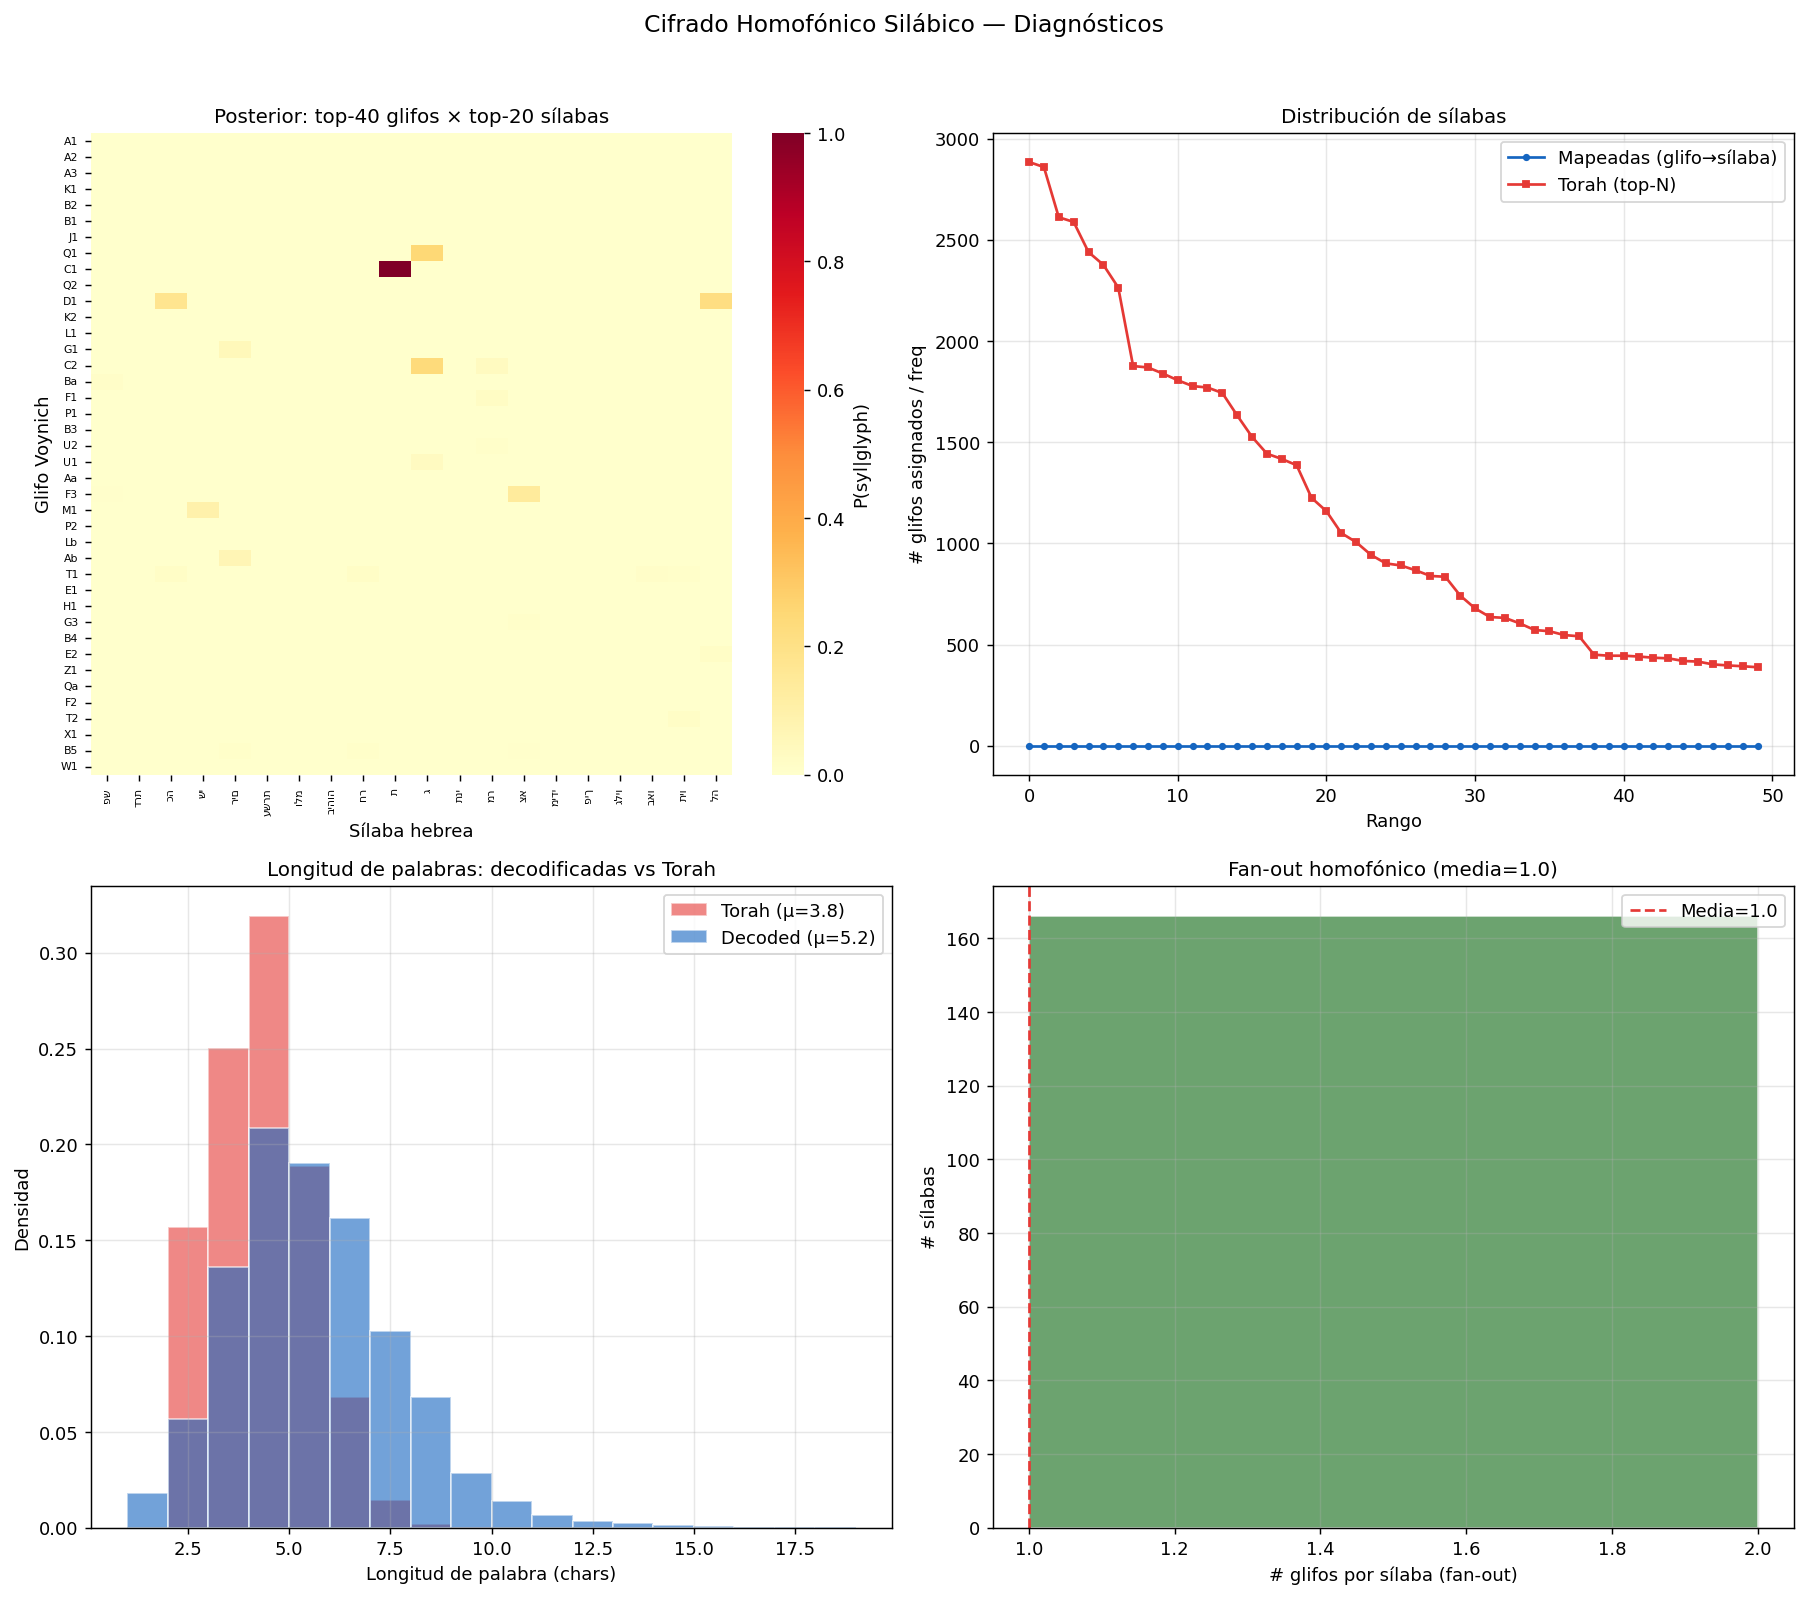

In [14]:
# ── Cell 14: Visualisations ──────────────────────────────────────────

fig, axes = plt.subplots(2, 2, figsize=(14, 12))

# Plot 1: Heatmap posterior (glyphs × top-20 syllables)
ax = axes[0, 0]
top_syls = sorted(set(mapping_sh.values()),
                  key=lambda s: sum(1 for g in mapping_sh if mapping_sh[g] == s),
                  reverse=True)[:20]
top_glyphs = sorted(VOCAB, key=lambda g: glyph_freq[g], reverse=True)[:40]
syl_labels = [''.join(s) for s in top_syls]

heatmap_data = np.zeros((len(top_glyphs), len(top_syls)))
for i, g in enumerate(top_glyphs):
    if g in posterior_sh:
        for syl, prob in posterior_sh[g].items():
            if syl in top_syls:
                j = top_syls.index(syl)
                heatmap_data[i, j] = prob

sns.heatmap(heatmap_data, ax=ax, cmap='YlOrRd',
            xticklabels=syl_labels, yticklabels=top_glyphs,
            cbar_kws={'label': 'P(syl|glyph)'})
ax.set_xlabel('Hebrew syllable')
ax.set_ylabel('Voynich glyph')
ax.set_title('Posterior: top-40 glyphs × top-20 syllables')
ax.tick_params(labelsize=6)

# Plot 2: Syllable frequency distribution (mapped vs Torah)
ax = axes[0, 1]
mapped_syl_freq = Counter(mapping_sh.values())
mapped_freqs = sorted(mapped_syl_freq.values(), reverse=True)
torah_syl_freqs = sorted([f for s, f in heb_syl_freq.most_common(len(mapped_syl_freq))], reverse=True)
x = range(min(len(mapped_freqs), 50))
ax.plot(x, mapped_freqs[:50], 'o-', color='#1565C0', markersize=3, label='Mapped (glyph→syllable)')
if torah_syl_freqs:
    ax.plot(x, torah_syl_freqs[:50], 's-', color='#E53935', markersize=3, label='Torah (top-N)')
ax.set_xlabel('Rank')
ax.set_ylabel('# assigned glyphs / freq')
ax.set_title('Syllable distribution')
ax.legend()
ax.grid(True, alpha=0.3)

# Plot 3: Word length distribution (decoded vs Torah)
ax = axes[1, 0]
decoded_lens = [len(state_sh.apply_word(w)) for w in palabras]
torah_lens = [len(w) for w in hebrew_words_full]
ax.hist(torah_lens, bins=range(1, 20), alpha=0.6, color='#E53935',
        label=f'Torah (μ={np.mean(torah_lens):.1f})', density=True, edgecolor='white')
ax.hist(decoded_lens, bins=range(1, 20), alpha=0.6, color='#1565C0',
        label=f'Decoded (μ={np.mean(decoded_lens):.1f})', density=True, edgecolor='white')
ax.set_xlabel('Word length (chars)')
ax.set_ylabel('Density')
ax.set_title('Word length: decoded vs Torah')
ax.legend()
ax.grid(True, alpha=0.3)

# Plot 4: Homophonic fan-out histogram
ax = axes[1, 1]
syl_to_glyphs = defaultdict(list)
for g, syl in mapping_sh.items():
    syl_to_glyphs[syl].append(g)
fanout = [len(gs) for gs in syl_to_glyphs.values()]
ax.hist(fanout, bins=range(1, max(fanout) + 2), color='#2E7D32', alpha=0.7, edgecolor='white')
ax.set_xlabel('# glyphs per syllable (fan-out)')
ax.set_ylabel('# syllables')
ax.set_title(f'Homophonic fan-out (mean={np.mean(fanout):.1f})')
ax.axvline(np.mean(fanout), color='#E53935', linestyle='--', label=f'Mean={np.mean(fanout):.1f}')
ax.legend()
ax.grid(True, alpha=0.3)

plt.suptitle('Syllabic Homophonic Cipher — Diagnostics', fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

In [15]:
# ── Cell 15: Export → syllabic_homophonic_resultados.json ──────────

# Serialize mapping: glyph → syllable as string
mapping_serializable = {g: ''.join(syl) for g, syl in mapping_sh.items()}

# Serialize posterior
posterior_serializable = {}
for g, dist in posterior_sh.items():
    posterior_serializable[g] = {''.join(syl): round(p, 4)
                                  for syl, p in dist.items() if p > 0.01}

# Fan-out statistics
syl_to_glyphs_export = defaultdict(list)
for g, syl in mapping_sh.items():
    syl_to_glyphs_export[''.join(syl)].append(g)
fanout_stats = {syl_str: len(gs) for syl_str, gs in syl_to_glyphs_export.items()}

resultados = {
    'metadata': {
        'notebook': '18_syllabic_homophonic.ipynb',
        'model': 'syllabic_homophonic_lstm',
        'language': 'hebrew',
        'description': 'Syllabic homophonic cipher: glyph → Hebrew syllable (many-to-one)',
        'hypothesis': 'Each Voynich glyph encodes a complete Hebrew syllable (2-3 chars)',
    },
    'syllable_inventory': {
        'n_syllables': len(SYLLABLE_VOCAB),
        'tp_threshold_percentile': 20,
        'tp_threshold_value': round(float(heb_tp_threshold), 4),
        'min_freq': 5,
        'position_distribution': dict(Counter(heb_syl_class.values())),
        'role_distribution': dict(Counter(syl_role.values())),
        'length_distribution': dict(Counter(len(s) for s in SYLLABLE_VOCAB)),
    },
    'neural_lm': {
        'architecture': 'LSTM 2-layer, embed=32, hidden=192, dropout=0.2',
        'n_params': sum(p.numel() for p in neural_lm.parameters()),
        'train_epochs': len(train_losses),
        'best_val_loss': float(best_val_loss),
    },
    'multi_seed_results': [{
        'seed': r['seed'], 'score': round(float(r['score']), 4),
        'K_eff': int(r['K_eff']), 'grammar': round(float(r['grammar']), 3),
        'n_roots': int(r['n_roots']),
        'roots_list': sorted(r['roots']),
        'iter_converged': int(r['iter_converged']),
        'elapsed': round(float(r['elapsed']), 1),
    } for r in multi_seed_results],
    'best_candidate': {
        'seed': int(BEST['seed']),
        'score': round(float(BEST['score']), 4),
        'K_eff': int(BEST['K_eff']),
        'grammar': round(float(BEST['grammar']), 3),
        'n_roots_quick': int(BEST['n_roots']),
    },
    'mcmc_results': {
        'n_chains': N_CHAINS,
        'n_iter': N_ITER,
        'burn_in': BURN_IN,
        'best_score': round(float(global_best_score), 4),
        'K_eff': len(set(global_best.mapping.values())),
        'pct_converged_rhat': round(float(pct_converged), 1),
        'chain_accept_rates': [round(float(ch['accept_rate']), 3) for ch in mcmc_chains],
    },
    'validation_scorecard': {s['Test']: s['Verdict'] for s in scorecard},
    'validation_details': {
        'collapse_mean_z': round(float(mean_z), 3),
        'ngram_percentile': round(float(pct_ngram), 1),
        'ngram_jsd': round(float(real_jsd), 4),
        'roots_matched': int(len(roots_matched_sh)),
        'enrichment': round(float(enrichment), 1),
        'cardinality_ratio': round(float(K_ratio), 3),
        'grammar_anchor_pct': round(float(pct_anchor), 3),
        'word_length_z': round(float(z_length), 3),
        'decoded_mean_length': round(float(decoded_mean), 2),
        'torah_mean_length': round(float(torah_mean), 2),
    },
    'scorecard_summary': f'{n_pass} PASS / {n_marg} MARGINAL / {n_fail} FAIL',
    'mapping': mapping_serializable,
    'posterior_top': posterior_serializable,
    'rhat': {g: round(float(v), 4) for g, v in rhat_sh.items()
             if isinstance(v, (int, float, np.floating)) and not np.isnan(v)},
    'fanout': fanout_stats,
    'homophonic_summary': {
        'mean_fanout': round(float(np.mean(list(fanout_stats.values()))), 2),
        'max_fanout': int(max(fanout_stats.values())),
        'n_unique_syllables_used': int(K_used),
        'n_syllables_with_multiple_glyphs': sum(1 for v in fanout_stats.values() if v > 1),
    },
    'multi_seed_summary': {
        'n_seeds': N_SEEDS,
        'score_mean': round(float(np.mean([r['score'] for r in multi_seed_results])), 4),
        'score_std': round(float(np.std([r['score'] for r in multi_seed_results])), 4),
        'roots_mean': round(float(np.mean([r['n_roots'] for r in multi_seed_results])), 1),
        'roots_std': round(float(np.std([r['n_roots'] for r in multi_seed_results])), 1),
        'K_eff_mean': round(float(np.mean([r['K_eff'] for r in multi_seed_results])), 1),
    },
    'comparison_table': comparison_rows,
}

class NumpyEncoder(json.JSONEncoder):
    def default(self, obj):
        if isinstance(obj, (np.integer,)): return int(obj)
        if isinstance(obj, (np.floating,)): return float(obj)
        if isinstance(obj, np.ndarray): return obj.tolist()
        if isinstance(obj, set): return sorted(obj)
        if isinstance(obj, tuple): return list(obj)
        return super().default(obj)

with open('syllabic_homophonic_resultados.json', 'w') as f:
    json.dump(resultados, f, indent=2, ensure_ascii=False, cls=NumpyEncoder)
print('Results exported to syllabic_homophonic_resultados.json')
print(f'Keys: {list(resultados.keys())}')

print(f'\n── Final summary ──')
print(f'Model: Syllabic Homophonic Cipher (glyph → Hebrew syllable)')
print(f'Syllable inventory: {len(SYLLABLE_VOCAB)} syllables')
print(f'Syllables used: {K_used} ({K_ratio:.0%} of inventory)')
print(f'Mean fan-out: {np.mean(list(fanout_stats.values())):.1f} glyphs/syllable')
print(f'Roots found: {len(roots_matched_sh)}')
print(f'Mean decoded length: {decoded_mean:.1f} chars (Torah: {torah_mean:.1f})')
print(f'Scorecard: {n_pass} PASS / {n_marg} MARGINAL / {n_fail} FAIL')
print(f'R-hat convergence: {pct_converged:.0f}%')

Resultados exportados a syllabic_homophonic_resultados.json
Keys: ['metadata', 'syllable_inventory', 'neural_lm', 'multi_seed_results', 'best_candidate', 'mcmc_results', 'validation_scorecard', 'validation_details', 'scorecard_summary', 'mapping', 'posterior_top', 'rhat', 'fanout', 'homophonic_summary', 'multi_seed_summary', 'comparison_table']

── Resumen final ──
Modelo: Cifrado Homofónico Silábico (glifo → sílaba hebrea)
Inventario silábico: 1811 sílabas
Sílabas usadas: 166 (9% del inventario)
Fan-out medio: 1.0 glifos/sílaba
Raíces encontradas: 1
Longitud media decodificada: 5.2 chars (Torah: 3.8)
Scorecard: 3 PASS / 1 MARGINAL / 2 FAIL
R-hat convergencia: 82%
